
# 🌸 АНАЛИЗ РОЗНИЧНОГО ЦВЕТОЧНОГО МАГАЗИНА · данные из Бизнес.Ру

**Один универсальный блокнот вместо трёх.** Он сам находит файлы в папке `data/`, сам определяет их тип (CSV / XLS / XLSX), сам разбирает «Движение товаров» на чеки и строит полный анализ: от KPI до детектора краж.

---

## 📑 Содержание

| Раздел | Что внутри |
|---|---|
| [0. Инструкция для новичка](#шаг0) | как запустить, что установить |
| [1. Где взять данные в Бизнес.Ру](#шаг1) | пошагово: какие отчёты, где кнопки, что выгружать |
| [2. Как воруют флористы](#шаг2) | 15 способов + какие именно цифры это выдают |
| [3. Настройки](#шаг3) | единственная ячейка, которую нужно править |
| [4–5. Загрузка данных](#шаг4) | чтение бизнесрушных файлов, разбор Движения товаров |
| [6. Контроль качества](#шаг6) | сходятся ли остатки, нет ли дыр |
| [7. KPI](#шаг7) | выручка, маржа, средний чек — плашками |
| [8. Динамика](#шаг8) | дни, недели, скользящее среднее |
| [9. Дни недели и часы](#шаг9) | когда продаём, когда пустуем |
| [10. Праздники](#шаг10) | вклад 14 февраля / 8 марта и т.д. |
| [11. ABC / XYZ / BCG](#шаг11) | какие товары кормят магазин |
| [12. Категории](#шаг12) | розы / срезка / упаковка / услуги |
| [13. Чек и корзинный анализ](#шаг13) | средний чек, допродажи, «что покупают вместе» |
| [14. Цены и маржа](#шаг14) | где теряем деньги, нулевые наценки |
| [15. Склад и закупка](#шаг15) | мёртвый товар, сколько заказать |
| [16. Прогноз выручки](#шаг16) | простой честный прогноз по дням недели |
| [17. 🔎 Детектор потерь и краж](#шаг17) | аномалии списаний, возвратов, кассы, по сотрудникам |
| [18. Резюме](#шаг18) | главные выводы текстом |
| [19. Экспорт в Excel](#шаг19) | все таблицы одним файлом по листам |
| [20. Куда расти](#шаг20) | Data Science, продуктовая аналитика, BI |

> ⚠️ Блокнот **ничего не отправляет** в интернет и не требует логина в Бизнес.Ру — он работает только с файлами, которые вы скачали руками.



<a id='шаг0'></a>
# 0. 🚀 Инструкция для новичка: как запустить за 3 минуты

1. **Установите Python** (один раз): скачайте с [python.org](https://www.python.org/downloads/) и поставьте галочку *«Add Python to PATH»*.
2. **Установите Jupyter Lab** (один раз). Откройте терминал / командную строку и выполните:
   ```bash
   pip install jupyterlab pandas numpy matplotlib openpyxl xlrd
   ```
   *(`xlrd` нужен, чтобы читать старые `.xls`, которые отдаёт Бизнес.Ру)*
3. **Положите файлы в папку `data/`** рядом с этим блокнотом (она уже есть). Имена файлов можно менять как угодно — блокнот найдёт их по ключевым словам: «движение», «продаж», «поступлен», «списан», «остатк», «контроль», «реализа», «прибыль».
4. **Запустите**: в терминале `jupyter lab`, откройте этот `.ipynb` и нажмите **«Run All»** (меню *Run → Run All Cells*).
5. Всё. Графики появятся под каждым разделом, а в конце — кнопка-ячейка, которая сохранит **Excel-отчёт со всеми таблицами**.

**Если ошибка «Не найден файл …»** — значит, нужный отчёт не лежит в `data/`. См. раздел 1, как его скачать.

**Если графики без русских букв** — перезапустите ядро (Kernel → Restart) и запустите заново.



<a id='шаг1'></a>
# 1. 📥 Где брать данные в Бизнес.Ру — подробно, по кнопкам

Ваш адрес: **https://w746008.business.ru** → слева вертикальное меню разделов: *Продажи, Закупки, Склад, Услуги, Финансы, Отчёты, Настройки…*

Общий принцип выгрузки везде одинаковый:

> **Раздел → нужный отчёт → задать период («Открыть») → кнопка «Настроить» или значок ⬇/«Экспорт» → формат «Файл Excel» или «CSV» → скачать.**

Ниже — карта всех нужных отчётов. Отмечено, что **обязательно**, а что полезно.

---

### 🥇 №1. «Движение товаров» — ОБЯЗАТЕЛЬНО (главный файл)

Это самый ценный отчёт: в нём **каждая продажа видна как отдельный чек** с датой и временем.

**Где:** меню **«Склад» → «Движение товаров»** (в некоторых версиях: **«Отчёты» → «Складские отчёты» → «Движение товара»**).

**Как выгрузить:**
1. Выберите **склад** (ваш розничный, например «Основной склад» / «Курская»). Не берите оптовый склад — сейчас анализируем только розницу.
2. Укажите **период** (например 01.10.2026 – 31.10.2026).
3. Нажмите **«Открыть»**, дождитесь таблички.
4. Над таблицей — кнопка **«Настроить» / шестерёнка** → убедитесь, что включены колонки: *Начальный остаток, Приход, Расход, Конечный остаток* (кол-во, себестоимость, сумма) и группировка **«по документам»** (чтобы под каждым товаром шли строки чеков).
5. Кнопка **«Экспорт» / значок скачивания** → **«Файл Excel (.xls)»** или CSV.

**Что внутри:** товар → склад → документы (чеки, поступления, списания, перемещения) с количеством и себестоимостью. Из него блокнот делает таблицу чеков.

📌 Именно этот файл Бизнес.Ру у вас уже отдаёт как `.xls` — блокнот читает и `.xls`, и `.csv`.

---

### 🥈 №2. «Продажи» (итоги по товарам) — ОБЯЗАТЕЛЬНО

Нужен, чтобы узнать **цены продажи** (в «Движении» есть только себестоимость!).

**Где:** меню **«Отчёты» → «Продажи»** (или **«Продажи» → «Отчёт по продажам»**, вкладка «Товары»).

**Как выгрузить:** период → «Открыть» → «Экспорт» → Excel/CSV. В отчёте должны быть колонки: *Наименование, Количество, Сумма* (выручка). 

---

### 🥉 №3. «Списания» — ОЧЕНЬ ЖЕЛАТЕЛЬНО (для раздела про воровство)

**Где:** меню **«Склад» → «Списания»** (либо в «Движении товаров» фильтр по типу документа «Списание»).

Выгружается список документов «Списание №… от дата» с суммами и причинами. Это основа контроля: **списания — законный способ «списать» украденное**.

---

### №4. «Поступления» — желательно (закупочные цены, поставщики)

**Где:** меню **«Закупки» → «Поступления»** (это как раз ваша страница `…/supply`). Там видно: от кого, когда, по какой цене пришло. Нужно для анализа закупочных цен и наценок по партиям.

---

### №5. «Остатки товаров» — желательно (срезы склада на дату)

**Где:** **«Склад» → «Остатки товаров»** (или «Отчёты» → «Остатки»). Нужен, чтобы сверять фактический остаток с расчётным и делать «слепые инвентаризации».

---

### №6. «Отчёт по реализациям» — по желанию (опт и юрлица)

**Где:** **«Отчёты» → «Продажи» → «По реализациям»**. Это не чеки розницы, а документы продажи оптом/юрлицам. Мы его показываем отдельно, чтобы не смешивать с розницей.

### №7. «Отчёт по прибыли» — по желанию

**Где:** **«Финансы» → «Отчёт о прибылях и убытках (P&L)»**. Даёт «правильную» прибыль со всеми расходами; наш блокнот считает валовую маржу по чекам — сверяйте.

### №8. Ваши кассовые таблицы (`Курская_Контроль_*.xlsx`)

Это ваш внутренний контроль кассы: нал/безнал по сотрудникам, ЗП, разница «расчёт/факт». Блокнот умеет читать такие листы («Касса»), если они лежат в `data/` — и использует их в разделе «Детектор потерь» (недостачи).

---

### ✅ Минимальный набор на каждый месяц

| Файл | Обязателен? | Даёт |
|---|---|---|
| Движение товаров | ✅ да | чеки, время, остатки, списания |
| Продажи | ✅ да | цены продажи → выручка и маржа по чекам |
| Списания | ➕ очень надо | контроль хищений через «порчу» |
| Поступления | ➕ | закупочные цены, поставщики |
| Остатки | ➕ | сверка склада |
| Реализации / P&L | ⚪ опционально | опт, прибыль целиком |

> 💡 **Лайфхак:** в Бизнес.Ру есть **«Настройки → Шаблоны отчётов»** — сохраните себе шаблон «Движение товаров» с нужными колонками и периодом «текущий месяц», тогда ежемесячная выгрузка = 2 клика.



<a id='шаг2'></a>
# 2. 🕵️ Как воруют флористы в цветочном магазине — способы и признаки

Цветочный магазин — зона высокого риска: **скоропортящийся товар, ручная сборка букетов, много «бесхозных» движений**. Ниже — реальные схемы, сгруппированные по этапам, и **цифры, по которым каждая схема видна в данных**. Раздел 17 блокнота автоматически ищет эти признаки.

### A. Хищения на кассе (самые частые)

| # | Способ | Как выглядит | Что «кричит» в данных |
|---|---|---|---|
| 1 | **«Минусовка» / отмена чека** | Пробил товар → сделал «возврат без клиента» → деньги в карман | Волна «возвратов» после закрытия смены; у одного сотрудника возвратов в разы больше, чем у других |
| 2 | **Непробитая продажа** | Продал «мимо кассы» | Товар уходит со склада (виден расход по Движению), а чека нет; **расхождение Движение vs Касса**; на инвентаризации — минус |
| 3 | **Занижение суммы** | Пробил дешевле / «на себя» по скидке | Доля скидок у одного продавца аномально высокая; средняя цена продажи конкретного товара ниже прайса у одной смены |
| 4 | **Подмена способа оплаты** | Наличку провели «безналом на свою карту» потом вернули | Недостача в кассе компенсируется «лишними» банковскими возвратами |
| 5 | **Работа «в парах»** | Один отвлекает, второй не пробивает | Провалы среднего чека в конкретные часы при конкретном сотруднике |

### B. Хищения через документы

| # | Способ | Как выглядит | Признак в данных |
|---|---|---|---|
| 6 | **Ложное списание «на порчу»** | Украли цветы → оформили как «засохло» | Резкие пики списаний в конце смены/месяца; списания у одного сотрудника ×N выше средних; списывается то, что обычно продаётся (розы, а не неликвид) |
| 7 | **Списание задним числом** | Документ «вчерашний», создан сегодня | Дата документа ≠ время создания; всплески сумм списаний «пачкой» одним днём |
| 8 | **Фиктивные возвраты поставщику** | «Вернули брак» — забрали домой | Возвраты поставщику без соответствующих поступлений этого товара |
| 9 | **Пересортица** | Заменили дорогую розу дешёвой в отчётности | Плюс одного SKU ровно равен минусу другого SKU в один день |
| 10 | **Завышение закупочной цены** (сговор с поставщиком) | В документе цена выше реальной, разницу делят | Цена закупки одного товара скачет между партиями без причины; сравнение «Поступления vs Прайс поставщика» |

### C. Хищения самим товаром

| # | Способ | Признак |
|---|---|---|
| 11 | **Прямная кража со склада/холодильника** | Минус на инвентаризации без документов; «дыра» между нач.+приход−расход и конечным остатком |
| 12 | **«Лишний» материал при сборке** | Расход зелени/упаковки на букет систематически выше нормы (норма зашивается в чек-лист) |
| 13 | **Букет «для себя»** | Сборка без чека: куплены комплектующие, а продажи готового букета нет | 
| 14 | **Использование клиентских цветов** | Принесли на оформление/свадьбу — часть «не вернулась» |
| 15 | **Кража денег из кассы напрямую** | Недостача в кассовых таблицах (разница расчёт/факт < 0) |

### 🛡 Профилактика (что реально работает)

1. **Регулярные слепые инвентаризации** 1–2 раза в неделю по топ-20 ABC-товаров (розы, ходовая срезка) — без предупреждения.
2. **Видео над зоной сборки и холодильником** + правило: букет без чека не собирается.
3. **Все возвраты/отмены — только со старшим смены**, с указанием причины; журнал отмен.
4. **Списания «на порчу» — с фото** каждого букета и подписью двух человек.
5. **Ежедневная авто-сверка**: сумма чеков дня ≈ выручка кассы; расход по Движению ≈ продажи+списания. Любая разница > 1% — вопрос к смене.
6. **Матричная ротация** сотрудников по сменам и выходным — чтобы никто не «владел» одним участком.
7. **Мотивация через % от маржи, а не от выручки** — снижает соблазн занижать цены.
8. **Сравнение показателей между сотрудниками** (этот блокнот, раздел 17) — главный математический инструмент: воришка виден как статистический выброс.

> Этот блокнот — **детектор аномалий, а не обвинение**. Он показывает «подозрительные строки»; дальше — проверка глазами, камерой и инвентаризацией.



<a id='шаг3'></a>
# 3. ⚙️ Настройки — менять только здесь

Всё, что можно подкрутить, собрано в одной ячейке. Для первого запуска **ничего менять не нужно** — просто выполните её.


In [1]:

# ╔══════════════════════════════════════════════════════════════╗
# ║            НАСТРОЙКИ — МЕНЯТЬ ТОЛЬКО В ЭТОЙ ЯЧЕЙКЕ          ║
# ╚══════════════════════════════════════════════════════════════╝
DATA_DIR      = 'data'    # папка с выгрузками из Бизнес.Ру
DATE_FROM     = None      # None = со старта данных, или '2026-10-01'
DATE_TO       = None      # None = до конца данных,   или '2026-10-31'

TOP_N         = 15        # сколько товаров показывать в рейтингах
SLOW_DAYS     = 21        # нет продаж столько дней → товар «залёжался»
COVER_DAYS    = 4         # на сколько дней вперёд держать запас цветов
COVER_LOOKBACK = 28       # по продажам за сколько дней считать скорость
GLOBAL_MARKUP = 2.0       # запасная наценка ×2, если цены продажи нигде нет
MARGIN_TARGET = 40        # целевая маржинальность, % (для красной подсветки)

# Корзинный анализ
MIN_SUPPORT   = 0.003     # минимальная доля чеков для пары товаров
MIN_PAIR_COUNT = 5        # пара должна встретиться хотя бы в N чеках
EXCLUDE_FROM_BASKET = ['Услуги флориста']  # сборка есть почти в каждом чеке — портит связки

# Прогноз
FORECAST_DAYS = 14

# Детектор потерь (раздел 17)
WRITEOFF_SPIKE_KOEF = 2.0 # списание в N раз больше медианы дня = подозрение
RETURN_RATE_ALERT   = 5.0 # доля возвратов в чеках > X% у сотрудника = подозрение

EXPORT_XLSX   = True      # сохранить все таблицы в Excel (раздел 19)
OUTPUT_DIR    = 'output'

print('✅ Настройки загружены')


✅ Настройки загружены



<a id='шаг4'></a>
# 4. 📦 Библиотеки и помощники

Библиотеки — готовые наборы инструментов: `pandas` — «Excel внутри Python», `matplotlib` — графики. Ниже также функции-помощники. Бизнес.Ру отдаёт файлы «для людей» (слиянные заголовки, кодировка cp1251, числа через запятую) — функции учат всё это читать.

**Лучшее из ваших трёх блокнотов, оставленное здесь:**
* умный поиск файла по ключевому слову и определение кодировки (из `flowers_report(1)`);
* чтение `.xls/.xlsx/.csv` одной функцией `read_table_any` (из `flowers_retail_analysis`);
* автоматические категории товаров по названию (из `flowers_retail_analysis`);
* аккуратные русские форматтеры рублей/процентов (из `flowers_report(1)`).


In [2]:

import os, re, warnings
from pathlib import Path
from itertools import combinations
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker

warnings.filterwarnings('ignore')
try:
    display
except NameError:
    display = print

plt.rcParams.update({
    'font.family': 'DejaVu Sans', 'font.size': 11,
    'axes.titlesize': 13, 'axes.titleweight': 'bold',
    'axes.spines.top': False, 'axes.spines.right': False,
    'figure.facecolor': '#F8F9FA', 'axes.facecolor': '#F8F9FA',
    'axes.grid': True, 'grid.alpha': .4, 'grid.linestyle': '--',
})

PALETTE = ['#2563EB','#10B981','#F59E0B','#EF4444','#8B5CF6','#EC4899',
           '#06B6D4','#84CC16','#F97316','#6366F1','#14B8A6','#FBBF24']
ABC_COLORS = {'A':'#10B981','B':'#F59E0B','C':'#EF4444'}
DAYS_RU = ['Пн','Вт','Ср','Чт','Пт','Сб','Вс']

def rub(v):
    return '—' if pd.isna(v) else f'{v:,.0f} ₽'.replace(',', ' ')
def num_fmt(v):
    return '—' if pd.isna(v) else f'{v:,.0f}'.replace(',', ' ')
def pct(v):
    return '—' if pd.isna(v) else f'{v:.1f}%'
def fmt_rub_axis(x, pos=None):
    if abs(x) >= 1_000_000: return f'{x/1e6:.1f}М'
    if abs(x) >= 1_000:     return f'{x/1e3:.0f}К'
    return f'{x:.0f}'
def norm_name(s):
    return re.sub(r'[\s_]+',' ',str(s).lower().replace('ё','е')).strip()
def to_num(s):
    # '1 234,50 шт.' -> 1234.5 ; пусто -> NaN
    s = s.astype(str).str.replace(r'[^0-9,.\-]','',regex=True).str.replace(',', '.', regex=False)
    return pd.to_numeric(s, errors='coerce')
def scalar_num(v):
    if v is None or (isinstance(v,float) and np.isnan(v)): return 0.0
    try: return float(str(v).replace('\xa0','').replace(' ','').replace(',','.'))
    except ValueError: return 0.0

def find_file(*keywords, ext=('.csv','.xls','.xlsx')):
    # Ищет в DATA_DIR файл, в имени которого есть ЛЮБОЕ из ключевых слов.
    if not os.path.isdir(DATA_DIR):
        raise FileNotFoundError(f'Нет папки «{DATA_DIR}». Создайте её рядом с блокнотом и положите выгрузки.')
    for f in sorted(os.listdir(DATA_DIR)):
        fl = norm_name(f)
        if f.lower().endswith(ext) and not f.startswith('~'):
            for kw in keywords:
                if norm_name(kw) in fl:
                    return os.path.join(DATA_DIR, f)
    return None

def read_csv_smart(path, **kw):
    # CSV из Бизнес.Ру: разделитель ';', кодировка utf-8-sig или cp1251.
    last = None
    for enc in ('utf-8-sig','cp1251','utf-8'):
        try:
            return pd.read_csv(path, sep=';', encoding=enc, dtype=str, **kw)
        except UnicodeDecodeError as e:
            last = e
    raise RuntimeError(f'Не удалось прочитать {path}: {last}')

def read_table_any(path, header=None):
    # Универсальное чтение: .xls (xlrd), .xlsx (openpyxl), .csv — одним вызовом.
    p = Path(path); suf = p.suffix.lower()
    if suf == '.xls':
        return pd.read_excel(p, header=header, dtype=str, engine='xlrd')
    if suf == '.xlsx':
        return pd.read_excel(p, header=header, dtype=str, engine='openpyxl')
    return read_csv_smart(p, header=header)

# ---------- Автоматические категории по названию товара ----------
CATEGORY_RULES = [
    ('Услуги флориста',        r'флор\s*услуг|услуга'),
    ('Упаковка и аксессуары',  r'короб|конверт|открытк|пакет|пакт|сумк|кашпо|оазис|декоратив|кризал|грунт|подкормк|лент|ваза|топпер|сетка|плёнк|крафт'),
    ('Горшечные растения',     r'\d+\s*/\s*\d+|фаленопсис|антуриум|шефлер|спатифилиум|сансивиер|цимбидиум|шлюмбергер|эхиверия|инжир|азалия|ало[еэ]|агава|адениум|аглаонема|агапантус|агератум|акалия|алиум'),
    ('Розы',                   r'(^|\s)роз[аы]($|\s|[,/])|кустов'),
    ('Хризантемы',             r'хризантем'),
    ('Зелень и наполнители',   r'эвкалипт|папортник|папоротник|аспидистр|рускус|писташ|лист дуба|гипсофил|лимониум|грин трик|скимия|краспедия|танацетум|брасика|молочай|салал'),
]
def categorize(name):
    n = str(name).lower()
    for cat, pat in CATEGORY_RULES:
        if re.search(pat, n):
            return cat
    return 'Прочая срезка'

def barh_labels(ax, labels, values, colors, fmt=rub, pad=.01):
    labels, values = list(labels), list(values)
    ax.barh(labels, values, color=colors)
    top = max(values) if len(values) else 1
    for i, v in enumerate(values):
        ax.text(v + top*pad, i, fmt(v), va='center', fontsize=8.5)
    ax.set_xlim(0, top*1.28 if top > 0 else 1)

print('✅ Библиотеки и функции готовы')


✅ Библиотеки и функции готовы



## 4.1 Загрузка файла «Продажи» → цены продажи

Берём из него **цену и сумму продажи** каждого товара — ими «оцениваем» каждую позицию чека из Движения (в самом Движении только себестоимость).

Файл может быть двух видов, код понимает оба:
1. **Нормальная таблица** с заголовками («Наименование», «Количество», «Сумма»…);
2. **«Сломанная» выгрузка Бизнес.Ру**, где вместо названий товаров пустые ячейки, а имена «уехали» в соседнюю колонку (в ваших файлах именно так) — тогда имена восстанавливаются по строке-шапке.


In [3]:

def load_sales_prices(path):
    # читаем без заголовка — разберёмся сами
    raw = read_table_any(path)
    if isinstance(raw.columns[0], str):     # CSV прочитался с заголовком — вернём его как строку данных
        hdr = pd.DataFrame([raw.columns]); raw = pd.concat([hdr, raw], ignore_index=True)
    raw = raw.dropna(how='all')
    # находим строку-шапку: в ней есть слово «товар/услуга» или «наименование» и «кол-во/количество»
    hdr_idx = None
    for i in range(min(6, len(raw))):
        row = ' '.join(map(str, raw.iloc[i].values)).lower()
        if ('товар' in row and 'кол' in row) or 'наименован' in row:
            hdr_idx = i; break
    cols_map = {}
    if hdr_idx is not None:
        for j, v in raw.iloc[hdr_idx].items():
            s = norm_name(v)
            if s: cols_map[j] = s
        data = raw.iloc[hdr_idx+1:]
    else:
        data = raw
    def colid(*parts):
        for j, s in cols_map.items():
            if all(p in s for p in parts): return j
        return None
    jc = colid('товар') or colid('наименован') or colid('услуг')
    jq = colid('кол')
    jrev = colid('выручка', 'сумма') or colid('сумма')
    jprice = colid('выручка', 'цена')
    jcost = colid('себестоим', 'сумма')
    name_series = data[jc] if jc is not None else pd.Series(index=data.index, dtype=object)
    # если имена пустые — пытаемся восстановить из предыдущей колонки (частый баг выгрузки Бизнес.Ру)
    if jc is not None and name_series.isna().mean() > 0.5 and jc > 0:
        alt = data[jc-1]
        if alt.notna().mean() > 0.5:
            name_series = alt
    out = pd.DataFrame({
        'Товар': name_series.astype(str).str.replace(r'\s+', ' ', regex=True).str.strip(),
        'Кол-во': to_num(data[jq]) if jq is not None else np.nan,
        'Выручка': to_num(data[jrev]) if jrev is not None else np.nan,
        'Цена продажи': to_num(data[jprice]) if jprice is not None else np.nan,
        'Себестоимость, сумма': to_num(data[jcost]) if jcost is not None else np.nan,
    })
    out = out[out['Товар'].str.len() > 2]
    out = out[~out['Товар'].str.lower().str.contains('товар/услуг|наименован|итого')]
    out = out.dropna(subset=['Кол-во'])
    out = out.groupby('Товар', as_index=False).sum(numeric_only=True)
    mask = out['Цена продажи'].isna()
    out.loc[mask, 'Цена продажи'] = np.where(out.loc[mask,'Кол-во']>0,
                                             out.loc[mask,'Выручка']/out.loc[mask,'Кол-во'], np.nan)
    out = out[out['Цена продажи'].notna() & (out['Цена продажи']>0)].copy()
    out['key'] = out['Товар'].map(norm_name)
    return out

path_sales = find_file('продаж')
if path_sales is None:
    print('⚠️ Файл «Продажи» не найден — цена продажи будет оценена как себестоимость ×%.2f' % GLOBAL_MARKUP)
    sales_agg = pd.DataFrame(columns=['key','Товар','Кол-во','Выручка','Цена продажи'])
else:
    sales_agg = load_sales_prices(path_sales)
    print(f'✅ {os.path.basename(path_sales)}: {len(sales_agg)} товаров с ценой продажи; выручка по файлу ≈ {rub(sales_agg["Выручка"].sum())}')


✅ Продажи.csv: 65 товаров с ценой продажи; выручка по файлу ≈ 424 903 ₽



<a id='шаг4b'></a>
# 5. 🧾 Разбор «Движения товаров» — сердце анализа

Формат файла (как его видит Бизнес.Ру):

```
Товар «Альстрамерия, шт.»            ← строка-ИТОГ по товару: нач.остаток | приход | расход | кон.остаток
   Основной склад                     ← строка склада
      Чек №261... от 02.10.2026 17:13 ← строка ДОКУМЕНТА (чек / поступление / списание…)
      Чек №261... от 02.10.2026 19:18
   ...следующий товар...
```

Правила разбора, заложенные в код:
* строка с непустой колонкой **A** → новый товар (её итоги → таблица `stock`);
* строка с непустой колонкой **B** → склад (запоминается для следующих строк);
* строка с непустой колонкой **C** → документ. Если имя начинается с «Чек» / «Чек возврата» → строка продажи; «Списание» → строка списания; «Поступление» → закупка.
* **Возврат чека** = товар вернулся на склад → количество и себестоимость идут со знаком минус.


In [4]:

path_mv = find_file('движение')
if path_mv is None:
    raise FileNotFoundError('В папке data/ нет файла «Движение товаров»! Скачайте его: Склад → Движение товаров → Экспорт.')

mv = read_table_any(path_mv)          # читаем БЕЗ заголовка — шапок там две строки
mv = mv.loc[:, ~mv.columns.str.startswith('Unnamed')] if isinstance(mv.columns[0], str) else mv
mv.columns = list(range(mv.shape[1]))

# находим конец шапки: первая строка, где в колонке A написано «Наименование…»
starts = mv.index[mv[0].astype(str).str.contains('Наименован', case=False, na=False)]
start = (starts[0] + 2) if len(starts) else 2
mv = mv.iloc[start:].reset_index(drop=True)

is_item  = mv[0].notna() & (mv[0].astype(str).str.strip() != '')
is_wh    = mv[1].notna() & (mv[1].astype(str).str.strip() != '') & ~is_item
is_doc   = mv[2].notna() & (mv[2].astype(str).str.strip() != '') & ~is_item & ~is_wh

mv['item_id'] = is_item.cumsum()
mv['item_raw'] = mv[0].ffill()
mv['wh'] = mv.groupby('item_id')[1].transform(lambda s: s.dropna().iloc[0] if s.notna().any() else np.nan)

UNIT_RE = r',\s*(?:шт|кг|л|м|г|уп|компл|пара|рул|см)\.?\s*$'
def clean_item(s):
    return re.sub(UNIT_RE, '', str(s).strip(), flags=re.IGNORECASE).strip()

# ---------- Итоги по товарам (остатки/приход/расход) ----------
hdr = mv[is_item]
stock = pd.DataFrame({
    'Товар':            hdr[0].map(clean_item),
    'Нач. остаток':     to_num(hdr[4]).fillna(0),
    'Приход, шт':       to_num(hdr[7]).fillna(0),
    'Приход, ₽':        to_num(hdr[9]).fillna(0),
    'Расход, шт':       to_num(hdr[10]).fillna(0),
    'Расход (себест.)': to_num(hdr[12]).fillna(0),
    'Кон. остаток':     to_num(hdr[13]).fillna(0),
    'Остаток, ₽':       to_num(hdr[15]).fillna(0),
}).reset_index(drop=True)
stock['key'] = stock['Товар'].map(norm_name)
stock = stock.groupby('key', as_index=False).agg({
    'Товар':'first','Нач. остаток':'sum','Приход, шт':'sum','Приход, ₽':'sum',
    'Расход, шт':'sum','Расход (себест.)':'sum','Кон. остаток':'sum','Остаток, ₽':'sum'})
stock['Категория'] = stock['Товар'].map(categorize)

# ---------- Все документы ----------
DOC_RE = re.compile(r'^(?P<тип>[^№]+?)\s*№\s*(?P<номер>\S+)\s+от\s+(?P<дата>\d{2}\.\d{2}\.\d{4})(?:\s+(?P<время>\d{1,2}:\d{2}))?')
dc = mv[is_doc].copy()
doc_txt = dc[2].astype(str).str.replace('\xa0',' ').str.strip()
info = doc_txt.str.extract(DOC_RE)
parsed = info['тип'].notna()
print(f'Строк документов всего: {len(dc)}, распознано с датой: {int(parsed.sum())}, нераспознано: {int((~parsed).sum())}')

docs = pd.DataFrame({
    'Тип':     np.where(parsed, info['тип'].str.strip(), doc_txt.str.slice(0,40)),
    'Номер':   np.where(parsed, info['номер'], ''),
    'Дата':    pd.to_datetime(np.where(parsed, info['дата'], ''), format='%d.%m.%Y', errors='coerce'),
    'Час':     pd.to_numeric(info['время'].str.split(':').str[0], errors='coerce'),
    'Товар':   dc['item_raw'].map(clean_item).values,
    'Склад':   dc['wh'].fillna('Основной склад').values,
    'Приход, шт': to_num(dc[7]).fillna(0).values,
    'Приход, ₽':  to_num(dc[9]).fillna(0).values,
    'Расход, шт': to_num(dc[10]).fillna(0).values,
    'Расход (себест.)': to_num(dc[12]).fillna(0).values,
})
docs['key'] = docs['Товар'].map(norm_name)
docs['Тип_norm'] = docs['Тип'].str.lower()
docs['Это_чек']      = docs['Тип_norm'].str.startswith('чек') & ~docs['Тип_norm'].str.contains('возврат')
docs['Это_возврат']  = docs['Тип_norm'].str.contains('возврат')
docs['Это_списание'] = docs['Тип_norm'].str.contains('списан')
docs['Это_поступление'] = docs['Тип_norm'].str.contains('поступлен')

print('Типы документов:', dict(docs['Тип'].value_counts().head(8)))

# ---------- Подсказка, если в выгрузке нет списаний/поступлений ----------
non_check = docs[~(docs['Это_чек']|docs['Это_возврат'])]
if len(non_check)==0:
    print('ℹ️ В «Движении товаров» есть ТОЛЬКО чеки. Это нормально: значит, выгрузка сделана с фильтром по типу документа.')
    print('   Списания и поступления блокнот возьмёт из отдельных файлов «Списания…» и «Поступления…» (см. ячейку 5.1).')

# ---------- Таблица чековых позиций (строки продаж) ----------
ch = docs[docs['Это_чек'] | docs['Это_возврат']].copy()
lines = pd.DataFrame({
    'check_key': ch['Номер'].values,
    'Дата': ch['Дата'].values,
    'Час': ch['Час'].values,
    'Товар': ch['Товар'].values,
    'Склад': ch['Склад'].values,
    'Возврат': ch['Это_возврат'].values,
    'Кол-во': np.where(ch['Это_возврат'], -ch['Приход, шт'], ch['Расход, шт']),
    'Себестоимость': np.where(ch['Это_возврат'], -ch['Приход, ₽'], ch['Расход (себест.)']),
})
lines['key'] = lines['Товар'].map(norm_name)
lines = lines.merge(sales_agg[['key','Цена продажи']], on='key', how='left')
lines['Цена известна'] = lines['Цена продажи'].notna()
uc = np.where(lines['Кол-во'].abs() > 0, lines['Себестоимость']/lines['Кол-во'].replace(0,np.nan), np.nan)
lines['Цена продажи'] = lines['Цена продажи'].fillna(pd.Series(uc, index=lines.index).fillna(0) * GLOBAL_MARKUP)
lines['Выручка'] = lines['Кол-во'] * lines['Цена продажи']
lines['Маржа']   = lines['Выручка'] - lines['Себестоимость']
lines['Категория'] = lines['Товар'].map(categorize)

print(f'✅ Позиций в чеках: {num_fmt(len(lines))} | Чеков: {num_fmt(lines["check_key"].nunique())} | '
      f'Товаров в остатках: {len(stock)}')
print(f'   Период: {lines["Дата"].min():%d.%m.%Y} — {lines["Дата"].max():%d.%m.%Y}')
print(f'   Цена продажи известна для {lines["Цена известна"].mean()*100:.1f}% позиций')


Строк документов всего: 535, распознано с датой: 535, нераспознано: 0
Типы документов: {'Чек': np.int64(535)}
ℹ️ В «Движении товаров» есть ТОЛЬКО чеки. Это нормально: значит, выгрузка сделана с фильтром по типу документа.
   Списания и поступления блокнот возьмёт из отдельных файлов «Списания…» и «Поступления…» (см. ячейку 5.1).
✅ Позиций в чеках: 535 | Чеков: 248 | Товаров в остатках: 478
   Период: 01.10.2026 — 14.10.2026
   Цена продажи известна для 78.3% позиций



<a id='шаг5b'></a>
## 5.1 Дополнительные файлы (если лежат в `data/`) — грузятся сами

Блокнот универсален: **любое сочетание файлов работает**. Нет файла — раздел просто вежливо пропустит себя.


In [5]:

extra = {}

# Поступления (закупки)
p = find_file('поступлен')
if p:
    df_in = read_table_any(p)
    extra['Поступления'] = df_in
    print(f'✅ Поступления: {os.path.basename(p)} ({len(df_in)} строк)')

# Списания (отдельным отчётом)
p = find_file('списан')
if p:
    df_out = read_table_any(p)
    extra['Списания'] = df_out
    print(f'✅ Списания: {os.path.basename(p)} ({len(df_out)} строк)')

# Остатки (срез склада)
p = find_file('остатк')
if p:
    df_st = read_table_any(p)
    extra['Остатки'] = df_st
    print(f'✅ Остатки: {os.path.basename(p)} ({len(df_st)} строк)')

# Реализации (опт)
p = find_file('реализа')
if p:
    df_rl = read_table_any(p)
    extra['Реализации'] = df_rl
    print(f'✅ Реализации (опт): {os.path.basename(p)} ({len(df_rl)} строк)')

# P&L / прибыль
p = find_file('прибыл')
if p:
    extra['Прибыль'] = read_table_any(p)
    print(f'✅ Прибыль: {os.path.basename(p)}')

# Кассовый контроль (ваши *.xlsx со словом «контроль»)
cash = None
p = find_file('контроль', ext=('.xlsx','.xls'))
if p:
    try:
        raw = pd.read_excel(p, sheet_name='Касса', header=None)
        hdr_rows = raw.index[raw.iloc[:,0].astype(str).str.strip().eq('Дата')]
        if len(hdr_rows):
            h = hdr_rows[0]
            d = raw.iloc[h+1:].copy()
            d.columns = [str(c).strip() for c in raw.iloc[h]]
            d = d[pd.to_datetime(d['Дата'], errors='coerce').notna()].copy()
            d['Дата'] = pd.to_datetime(d['Дата'])
            for c in d.columns:
                if any(w in c.lower() for w in ['итого','нал','безнал','расход','внесено','изъято','зп','остаток','разница']):
                    d[c] = to_num(d[c]).fillna(0)
            cash = d
            print(f'✅ Кассовый контроль: {os.path.basename(p)} ({len(cash)} смен)')
    except Exception as e:
        print(f'⚠️ Не удалось прочитать кассу: {e}')
else:
    print('ℹ️ Файл кассового контроля не найден — часть проверок в разделе 17 будет по данным Бизнес.Ру.')


✅ Поступления: Поступления.csv (299 строк)
✅ Списания: Списания товаров.csv (243 строк)
✅ Остатки: Остатки товаров.csv (466 строк)
✅ Реализации (опт): Отчет по реализациям.csv (1 строк)
✅ Прибыль: Отчет по прибыли.csv
✅ Кассовый контроль: Курская_Контроль_Октябрь.xlsx (31 смен)



<a id='шаг6'></a>
# 6. 🔎 Фильтр по периоду и проверка качества данных

**Правило №1 Data Science: сначала проверяем данные, потом делаем выводы.** Здесь мы:
1. режем период из настроек;
2. сверяем бухгалтерское тождество **нач.остаток + приход − расход = кон.остаток** по каждому товару (несходимость = потерянные/лишние документы — потенциальные хищения!);
3. считаем покрытие данными (все ли дни есть).


In [6]:

_dmin = pd.to_datetime(DATE_FROM) if DATE_FROM else lines['Дата'].min()
_dmax = pd.to_datetime(DATE_TO)   if DATE_TO   else lines['Дата'].max()
df_s = lines[(lines['Дата'] >= _dmin) & (lines['Дата'] <= _dmax)].copy()
docs_f = docs[(docs['Дата'] >= _dmin) & (docs['Дата'] <= _dmax)].copy()
print(f'✅ Рабочий период: {_dmin:%d.%m.%Y} — {_dmax:%d.%m.%Y} | позиций: {num_fmt(len(df_s))} | чеков: {num_fmt(df_s["check_key"].nunique())}')

# --- сверка тождества остатков ---
st_f = stock.copy()
expected = st_f['Нач. остаток'] + st_f['Приход, шт'] - st_f['Расход, шт']
st_f['Невязка, шт'] = st_f['Кон. остаток'] - expected
bad = st_f[(st_f['Невязка, шт'].abs() > 0.5) & ((st_f['Нач. остаток']+st_f['Приход, шт']+st_f['Расход, шт']) > 0)]
print(f'🔍 Товаров с расхождением формулы остатков: {len(bad)} (в норме должно быть 0; источник — неполная выгрузка либо «серые» документы)')
if len(bad):
    display(bad[['Товар','Нач. остаток','Приход, шт','Расход, шт','Кон. остаток','Невязка, шт']].sort_values('Невязка, шт').head(10))

# --- покрытие днями ---
all_days = pd.date_range(_dmin.normalize(), _dmax.normalize(), freq='D')
days_with_sales = df_s['Дата'].dt.normalize().nunique()
print(f'📅 Дней в периоде: {len(all_days)}, с продажами: {days_with_sales} ({days_with_sales/len(all_days)*100:.0f}%)')

quality_notes = []
if days_with_sales < len(all_days):
    quality_notes.append('Есть дни без продаж — возможно, выходные или пропуск выгрузки')
if not df_s['Цена известна'].all():
    quality_notes.append(f'Для {(1-df_s["Цена известна"].mean())*100:.0f}% позиций цена продажи оценена (нет в отчёте «Продажи»)')
if len(bad):
    quality_notes.append(f'{len(bad)} товаров с невязкой остатков — проверить полноту документов')
if quality_notes:
    print('⚠️ Замечания к качеству:'); [print('   •', q) for q in quality_notes]
else:
    print('✅ Качество данных: замечаний нет')


✅ Рабочий период: 01.10.2026 — 14.10.2026 | позиций: 535 | чеков: 248
🔍 Товаров с расхождением формулы остатков: 0 (в норме должно быть 0; источник — неполная выгрузка либо «серые» документы)
📅 Дней в периоде: 14, с продажами: 13 (93%)
⚠️ Замечания к качеству:
   • Есть дни без продаж — возможно, выходные или пропуск выгрузки
   • Для 22% позиций цена продажи оценена (нет в отчёте «Продажи»)



<a id='шаг7'></a>
# 7. 💰 KPI — главные цифры магазина

Как читать:
* **Выручка** — сколько принесли деньги;
* **Себестоимость** — почём куплено;
* **Валовая маржа** = выручка − себестоимость (ещё не прибыль: из неё платят аренду, ЗП);
* **Маржинальность %** = маржа ÷ выручка (для цветов норма 30–50%);
* **Средний чек** — выручка одного визита;
* **Чеков** — сколько визитов (трафик).


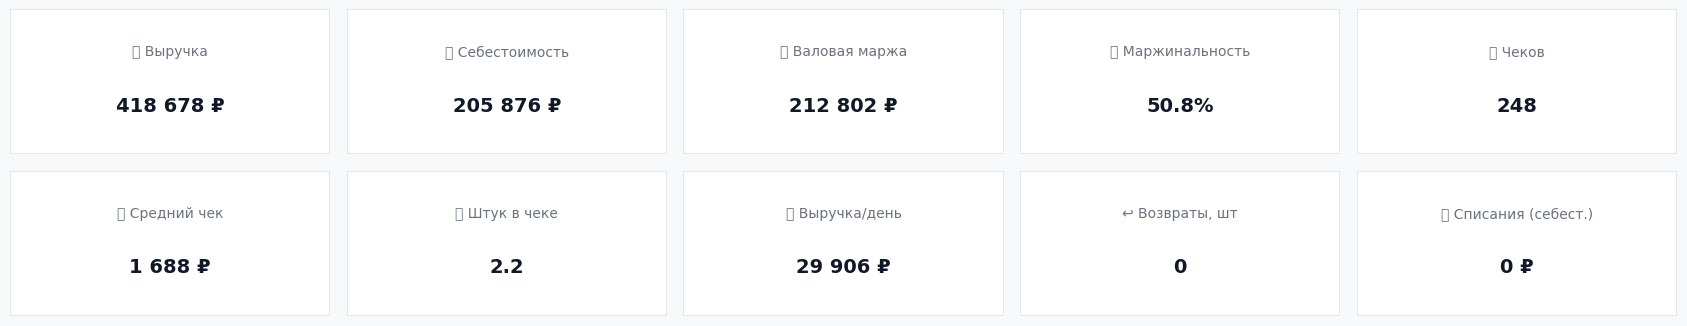

Период: 14 дн. | Списаний на 0 ₽ = 0.0% от себестоимости продаж


In [7]:

total_rev    = df_s['Выручка'].sum()
total_cost   = df_s['Себестоимость'].sum()
total_margin = total_rev - total_cost
margin_pct   = total_margin / total_rev * 100 if total_rev else np.nan
n_checks     = df_s['check_key'].nunique()
avg_check    = total_rev / n_checks if n_checks else np.nan
items_per_chk = len(df_s) / n_checks if n_checks else np.nan
days_span    = (df_s['Дата'].max().normalize() - df_s['Дата'].min().normalize()).days + 1
ret_qty      = df_s.loc[df_s['Возврат'], 'Кол-во'].abs().sum()
sold_qty     = df_s.loc[~df_s['Возврат'], 'Кол-во'].sum()
writeoff     = docs_f[docs_f['Это_списание']]
wo_sum       = writeoff['Расход (себест.)'].sum()
wo_source    = 'Движение товаров'
if wo_sum == 0 and 'Списания' in extra:      # берём из отдельного отчёта Бизнес.Ру «Списания»
    sb = extra['Списания']
    cand = [c for c in sb.columns if any(w in norm_name(c) for w in ['сумма','итого'])]
    s_num = to_num(sb[cand[0]]) if cand else pd.Series(dtype=float)
    wo_sum = float(s_num.sum(skipna=True))
    wo_source = 'файл «Списания»'

kpis = [('💰 Выручка', rub(total_rev)), ('📉 Себестоимость', rub(total_cost)),
        ('🟢 Валовая маржа', rub(total_margin)), ('📊 Маржинальность', pct(margin_pct)),
        ('🧾 Чеков', num_fmt(n_checks)), ('🎯 Средний чек', rub(avg_check)),
        ('📦 Штук в чеке', f'{items_per_chk:.1f}'), ('📈 Выручка/день', rub(total_rev/days_span)),
        ('↩️ Возвраты, шт', num_fmt(ret_qty)),
        ('🗑 Списания (себест.)', rub(wo_sum)),
        ]
fig, axes = plt.subplots(2, 5, figsize=(17, 3.4))
for ax, (t, v) in zip(axes.ravel(), kpis):
    ax.axis('off')
    ax.add_patch(plt.Rectangle((0,0),1,1, transform=ax.transAxes, fc='white', ec='#E5E7EB', lw=1.5))
    ax.text(.5,.68,t,ha='center',fontsize=10,color='#6B7280',transform=ax.transAxes)
    ax.text(.5,.3,v,ha='center',fontsize=14,fontweight='bold',color='#111827',transform=ax.transAxes)
plt.tight_layout(); plt.show()
print(f'Период: {days_span} дн. | Списаний на {rub(wo_sum)} = {wo_sum/total_cost*100 if total_cost else 0:.1f}% от себестоимости продаж')



<a id='шаг8'></a>
# 8. 📈 Динамика выручки и маржи по дням

Столбики — дни; линия — **скользящее среднее за 7 дней** (сглаживает «шум» дней недели: видно тренд, а не только праздники).


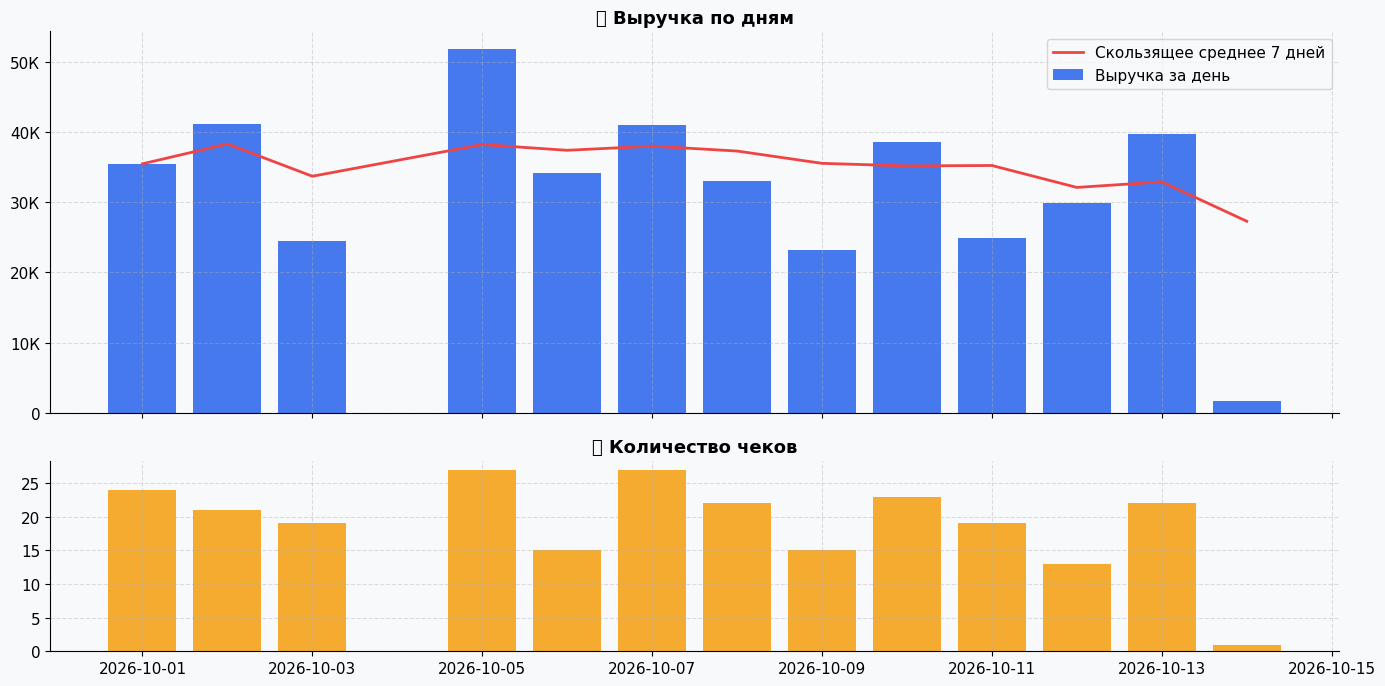

In [8]:

daily = df_s.groupby(df_s['Дата'].dt.normalize()).agg(
    Выручка=('Выручка','sum'), Маржа=('Маржа','sum'),
    Чеков=('check_key','nunique'), Штук=('Кол-во','sum')).reset_index().rename(columns={'Дата':'День'})
daily['MA7'] = daily['Выручка'].rolling(7, min_periods=1).mean()

fig, axes = plt.subplots(2,1, figsize=(14,7), sharex=True, gridspec_kw={'height_ratios':[2,1]})
ax = axes[0]
ax.bar(daily['День'], daily['Выручка'], color=PALETTE[0], alpha=.85, label='Выручка за день')
ax.plot(daily['День'], daily['MA7'], color=PALETTE[3], lw=2, label='Скользящее среднее 7 дней')
ax.yaxis.set_major_formatter(mticker.FuncFormatter(fmt_rub_axis))
ax.set_title('💸 Выручка по дням'); ax.legend()
ax2 = axes[1]
ax2.bar(daily['День'], daily['Чеков'], color=PALETTE[2], alpha=.85)
ax2.set_title('🧾 Количество чеков'); 
plt.tight_layout(); plt.show()



<a id='шаг9'></a>
# 9. 🗓 Дни недели и часы работы

Считаем **среднюю** выручку на день такого типа weekday (а не сумму — иначе «длинные» дни выглядят лучше). Тепловая карта «день × час» подсказывает, когда нужны дополнительные руки, а когда флорист свободен для онлайн-заказов.


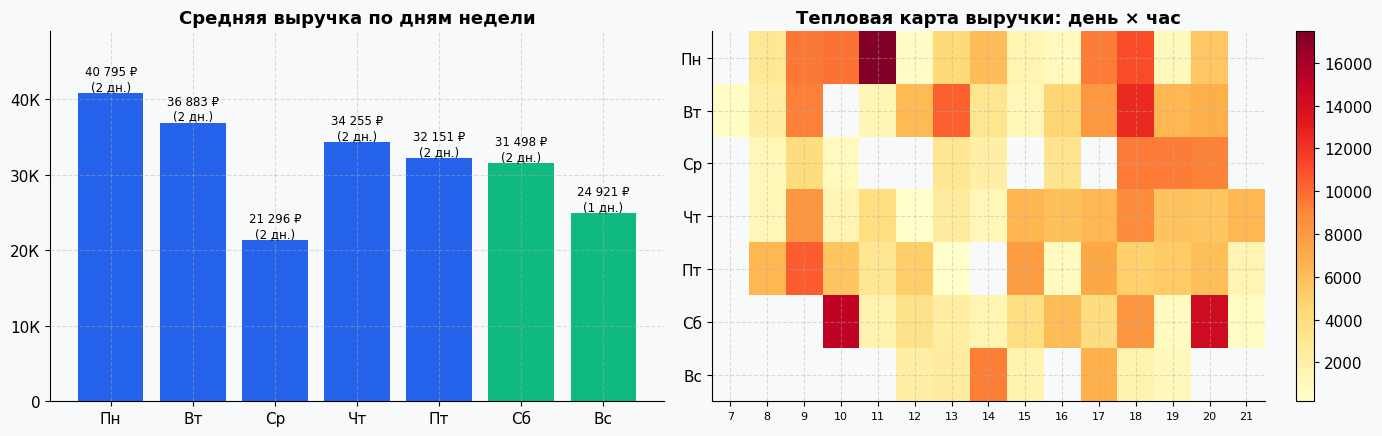

In [9]:

daily['День недели'] = daily['День'].dt.dayofweek
has = daily[daily['Чеков']>0]
dow = has.groupby('День недели').agg(Выручка=('Выручка','mean'), Чеков=('Чеков','mean'), Дней=('Выручка','size'))
dow = dow.reindex(range(7)).fillna(0)

fig, axes = plt.subplots(1,2, figsize=(14,4.5))
ax = axes[0]
cols = [PALETTE[1] if d in (5,6) else PALETTE[0] for d in dow.index]
bars = ax.bar(DAYS_RU, dow['Выручка'], color=cols)
for b,v,n in zip(bars, dow['Выручка'], dow['Дней']):
    ax.text(b.get_x()+b.get_width()/2, v, f'{rub(v)}\n({int(n)} дн.)', ha='center', va='bottom', fontsize=8.5)
ax.set_title('Средняя выручка по дням недели'); ax.yaxis.set_major_formatter(mticker.FuncFormatter(fmt_rub_axis))
ax.set_ylim(0, dow['Выручка'].max()*1.2 if dow['Выручка'].max()>0 else 1)

hc = df_s[df_s['Час'].notna()].copy(); hc['hour']=hc['Час'].astype(int); hc['wd']=hc['Дата'].dt.dayofweek
pivot = hc.pivot_table(index='wd', columns='hour', values='Выручка', aggfunc='sum').reindex(range(7))
hours = pivot.columns
hm = axes[1].imshow(pivot.values, cmap='YlOrRd', aspect='auto')
axes[1].set_yticks(range(7)); axes[1].set_yticklabels(DAYS_RU)
axes[1].set_xticks(range(len(hours))); axes[1].set_xticklabels([str(h) for h in hours], fontsize=8)
axes[1].set_title('Тепловая карта выручки: день × час')
plt.colorbar(hm, ax=axes[1], fraction=.05)
plt.tight_layout(); plt.show()



<a id='шаг10'></a>
# 10. 🎉 Праздники — главные пики цветочного бизнеса

Для каждого праздника смотрим окно «N дней до + сам день». Цветочные даты: 14.02, 23.02, 08.03 (+ неделя до), последний воскресный ноября (День матери), 1 сентября, Новый год.


In [10]:

def holidays_for_year(y):
    nov30 = pd.Timestamp(y,11,30)
    mothers = nov30 - pd.Timedelta(days=nov30.dayofweek)
    return {'14 февраля': (pd.Timestamp(y,2,10), pd.Timestamp(y,2,14)),
            '23 февраля': (pd.Timestamp(y,2,21), pd.Timestamp(y,2,23)),
            '8 марта':    (pd.Timestamp(y,3,2),  pd.Timestamp(y,3,8)),
            'День матери':(mothers - pd.Timedelta(days=4), mothers),
            '1 сентября': (pd.Timestamp(y,8,30), pd.Timestamp(y,9,1)),
            'Новый год':  (pd.Timestamp(y,12,26), pd.Timestamp(y,12,31))}

yrs = sorted(set(df_s['Дата'].dt.year))
hol_ranges = {name:(a,b) for y in yrs for name,(a,b) in holidays_for_year(y).items()}
avg_day = daily.loc[daily['Чеков']>0,'Выручка'].mean()
rows=[]
for name,(a,b) in hol_ranges.items():
    win = daily[(daily['День']>=a)&(daily['День']<=b)]
    if len(win):
        rows.append({'Праздник': f'{name} {a.year}', 'Выручка': win['Выручка'].sum(),
                     'Дней': len(win), 'Выручка/день': win['Выручка'].sum()/len(win)})
hol = pd.DataFrame(rows) if rows else pd.DataFrame(columns=['Праздник','Выручка','Дней','Выручка/день'])
if len(hol):
    hol = hol.sort_values('Выручка', ascending=False)
    fig, ax = plt.subplots(figsize=(11, max(3, .5*len(hol))))
    bars = ax.barh(hol['Праздник'][::-1], hol['Выручка/день'][::-1], color=PALETTE[5])
    for i,(v,base) in enumerate(zip(hol['Выручка/день'][::-1], hol['Выручка/день'][::-1]/avg_day)):
        ax.text(v, i, f'  {rub(v)}  (×{base:.1f} к обычному дню)', va='center', fontsize=9)
    ax.set_title(f'🎉 Средняя выручка в день праздника против обычного дня ({rub(avg_day)})')
    ax.xaxis.set_major_formatter(mticker.FuncFormatter(fmt_rub_axis)); ax.set_xlim(0, hol['Выручка/день'].max()*1.45)
    plt.tight_layout(); plt.show()
    display(hol.reset_index(drop=True))
else:
    print('ℹ️ В выбранном периоде нет праздничных окон.')


ℹ️ В выбранном периоде нет праздничных окон.



<a id='шаг11'></a>
# 11. 🏆 ABC, XYZ и матрица ABC×XYZ

* **ABC (Парето):** A — товары, дающие первые 80% выручки (или маржи), B — следующие 15%, C — последние 5%.
* **XYZ:** насколько стабильны недельные продажи (CV = коэффициент вариации): X ≤ 50% — стабильный, Y ≤ 100%, Z — хаотичный.
* **AX — звезда** (много и стабильно → никогда не должен заканчиваться), **CZ — кандидат на выезд** из ассортимента.


KeyError: 0

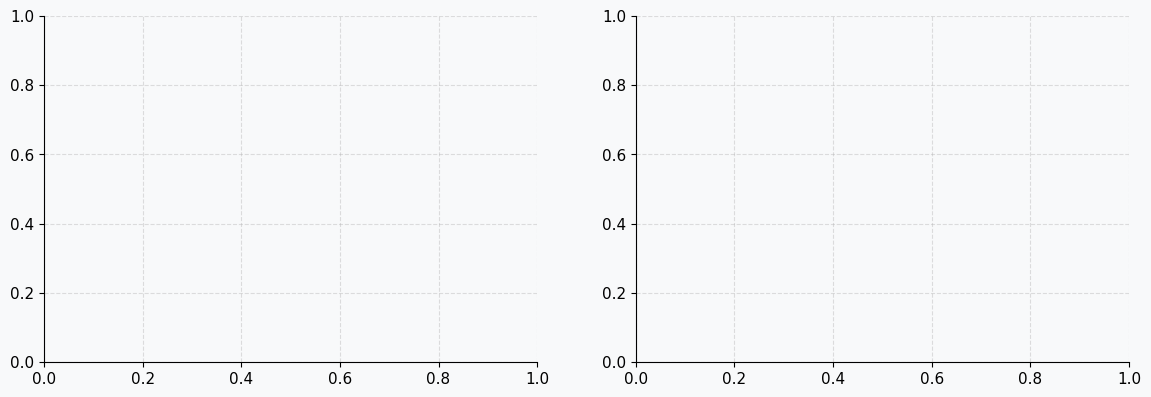

In [11]:

def abc_table(data, value_col):
    t = data.groupby('Товар').agg(Выручка=('Выручка','sum'), Маржа=('Маржа','sum'),
                                  Продано=('Кол-во','sum'), Чеков=('check_key','nunique')).reset_index()
    t = t.sort_values(value_col, ascending=False).reset_index(drop=True)
    t['Доля %'] = t[value_col]/t[value_col].sum()*100
    t['Накопл %'] = t['Доля %'].cumsum()
    t['Класс'] = np.where(t['Накопл %']<=80,'A', np.where(t['Накопл %']<=95,'B','C'))
    return t

abc_rev   = abc_table(df_s, 'Выручка')
abc_marg  = abc_table(df_s, 'Маржа')

fig, axes = plt.subplots(1,2, figsize=(14,4.5))
for ax, t, ttl in [(axes[0], abc_rev,'ABC по ВЫРУЧКЕ'), (axes[1], abc_marg,'ABC по МАРЖЕ')]:
    g = t.groupby('Класс').agg(Товаров=('Товар','size'), Доля=(t.columns[t.columns=='Доля %'][0],'sum'))
    ax.pie(g['Доля'], labels=[f'{k}\n{int(v[0])} тов., {v[1]:.0f}%' for k,v in g.iterrows()],
           colors=[ABC_COLORS[k] for k in g.index], startangle=90, textprops={'fontsize':10})
    ax.set_title(ttl)
plt.tight_layout(); plt.show()

top = abc_rev.head(TOP_N)
fig, ax = plt.subplots(figsize=(11, .4*len(top)+1.5))
barh_labels(ax, top['Товар'], top['Выручка'], [ABC_COLORS[c] for c in top['Класс']])
ax.invert_yaxis(); ax.set_title(f'🏆 Топ-{TOP_N} товаров по выручке (цвет = класс ABC)')
ax.xaxis.set_major_formatter(mticker.FuncFormatter(fmt_rub_axis)); plt.tight_layout(); plt.show()

# XYZ по неделям
wk = (df_s.assign(Неделя=df_s['Дата'] - pd.to_timedelta(df_s['Дата'].dt.dayofweek, unit='D'))
        .pivot_table(index='Товар', columns='Неделя', values='Кол-во', aggfunc='sum').fillna(0))
n_weeks = wk.shape[1]
xyz = pd.DataFrame({'средн': wk.mean(axis=1), 'cv': (wk.std(axis=1)/wk.mean(axis=1)*100)})
xyz['Класс XYZ'] = np.where(xyz['cv']<=50,'X', np.where(xyz['cv']<=100,'Y','Z'))
xyz.loc[xyz['средн']<=0,'Класс XYZ'] = 'Z'
mat = abc_rev[['Товар','Класс']].merge(xyz[['Класс XYZ']], left_on='Товар', right_index=True, how='left')
mat['Класс XYZ'] = mat['Класс XYZ'].fillna('Z')
ct = pd.crosstab(mat['Класс'], mat['Класс XYZ'])
fig, ax = plt.subplots(figsize=(6,4))
im = ax.imshow(ct.values, cmap='RdYlGn_r'); ax.set_xticks(range(ct.shape[1])); ax.set_xticklabels(ct.columns)
ax.set_yticks(range(ct.shape[0])); ax.set_yticklabels(ct.index)
for i in range(ct.shape[0]):
    for j in range(ct.shape[1]):
        ax.text(j,i,ct.values[i,j],ha='center',va='center',fontsize=12,fontweight='bold')
ax.set_title('Матрица ABC × XYZ (число товаров)'); ax.grid(False)
plt.tight_layout(); plt.show()
print('AX — «звёзды» (всегда в наличии), CZ — «хвост» (выводить из ассортимента).')
display(ct)



<a id='шаг12'></a>
# 12. 📂 Категории товаров

Категории определяются **автоматически по названию** (правила — в ячейке 4: розы, хризантемы, горшечные, зелень, упаковка, услуги…). Их можно дополнить своими словами в `CATEGORY_RULES`.


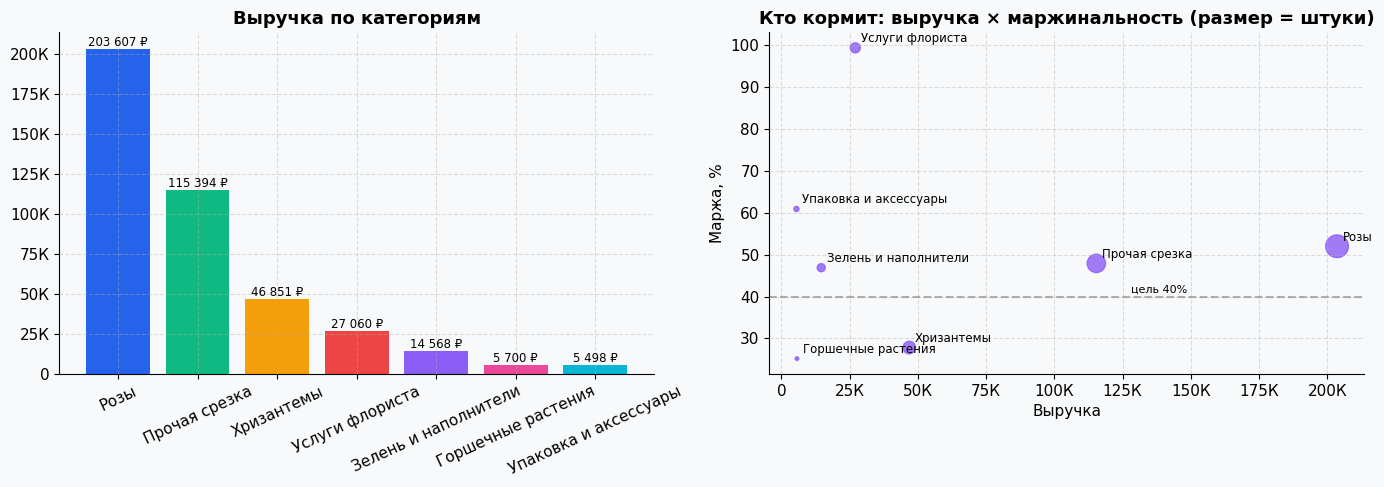

,Категория,Выручка,Маржа,Продано,Чеков,Маржа %
3,Розы,203607.46,105934.00,1001.0,127,52.028546
2,Прочая срезка,115394.33,55309.50,525.0,86,47.930865
6,Хризантемы,46851.07,13035.07,245.0,52,27.822353
5,Услуги флориста,27059.95,26902.95,157.0,78,99.419807
1,Зелень и наполнители,14567.98,6834.53,101.0,28,46.914740
0,Горшечные растения,5700.00,1436.00,11.0,7,25.192982
4,Упаковка и аксессуары,5497.54,3349.98,41.0,25,60.935982


In [ ]:

cat = df_s.groupby('Категория').agg(Выручка=('Выручка','sum'), Маржа=('Маржа','sum'),
                                    Продано=('Кол-во','sum'), Чеков=('check_key','nunique')).reset_index()
cat['Маржа %'] = cat['Маржа']/cat['Выручка']*100
cat = cat.sort_values('Выручка', ascending=False)
fig, axes = plt.subplots(1,2, figsize=(14,5))
ax = axes[0]
bars = ax.bar(cat['Категория'], cat['Выручка'], color=PALETTE[:len(cat)])
for b,v in zip(bars,cat['Выручка']):
    ax.text(b.get_x()+b.get_width()/2, v, rub(v), ha='center', va='bottom', fontsize=8.5)
ax.set_title('Выручка по категориям'); ax.tick_params(axis='x', rotation=25)
ax.yaxis.set_major_formatter(mticker.FuncFormatter(fmt_rub_axis))
ax = axes[1]
sc = ax.scatter(cat['Выручка'], cat['Маржа %'], s=cat['Продано'].clip(20,800)/3, color=PALETTE[4], alpha=.8)
for _,r in cat.iterrows():
    ax.annotate(r['Категория'], (r['Выручка'], r['Маржа %']), fontsize=8.5, xytext=(4,4), textcoords='offset points')
ax.axhline(MARGIN_TARGET, ls='--', color='gray', alpha=.6); ax.text(ax.get_xlim()[1]*.6, MARGIN_TARGET+1, f'цель {MARGIN_TARGET}%', fontsize=8)
ax.set_xlabel('Выручка'); ax.set_ylabel('Маржа, %'); ax.set_title('Кто кормит: выручка × маржинальность (размер = штуки)')
ax.xaxis.set_major_formatter(mticker.FuncFormatter(fmt_rub_axis))
plt.tight_layout(); plt.show()
display(cat)



<a id='шаг13'></a>
# 13. 🛒 Структура чека и Market Basket («что покупают вместе»)

* Распределение чеков по числу позиций — есть ли смысл учить допродавать.
* **Лифт (lift)** пары товаров = во сколько раз чаще они встречаются в одном чеке, чем случайно. Lift > 1.5 — сильная связка → готовые «наборы» и допродажи у кассы.


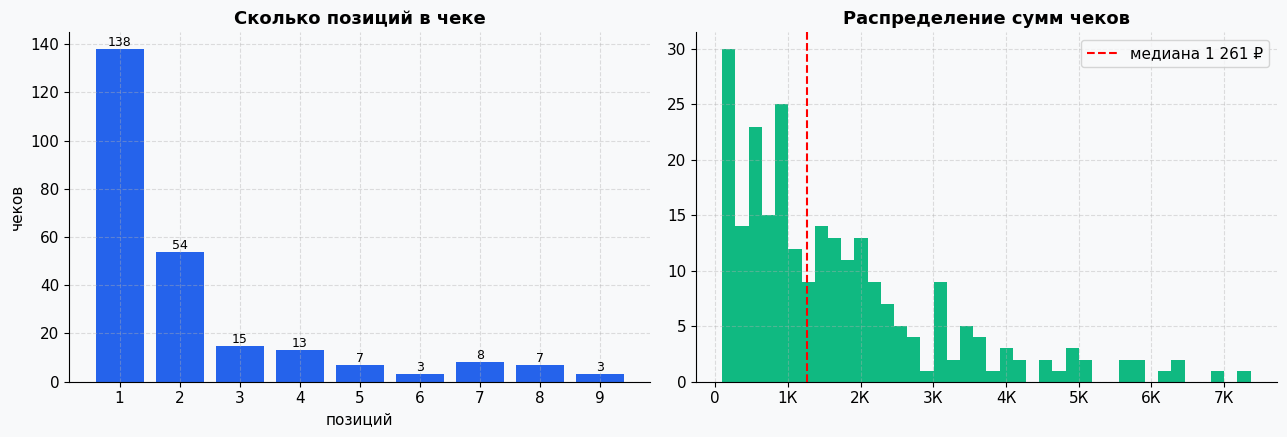

✅ Пар найдено: 8. Топ-10 связок:


,Товар A,Товар B,Чеков с парой,Поддержка %,Lift,Конф. A→B,Конф. B→A
0,Оазис,Сумки средние,6,2.49,26.78,66.67,100.00
3,Вакс-флаур,Гортензия К,7,2.90,7.63,53.85,41.18
6,Оазис,Хризантема кустовая,6,2.49,5.54,66.67,20.69
1,Альстрамерия,Гортензия К,6,2.49,4.05,28.57,35.29
4,Вакс-флаур,Хризантема кустовая,6,2.49,3.84,46.15,20.69
2,Альстрамерия,Хризантема кустовая,9,3.73,3.56,42.86,31.03
5,Гортензия К,Хризантема кустовая,5,2.07,2.44,29.41,17.24
7,"Кустовая роза Кения, шт. Размер: 60",Хризантема кустовая,5,2.07,2.19,26.32,17.24


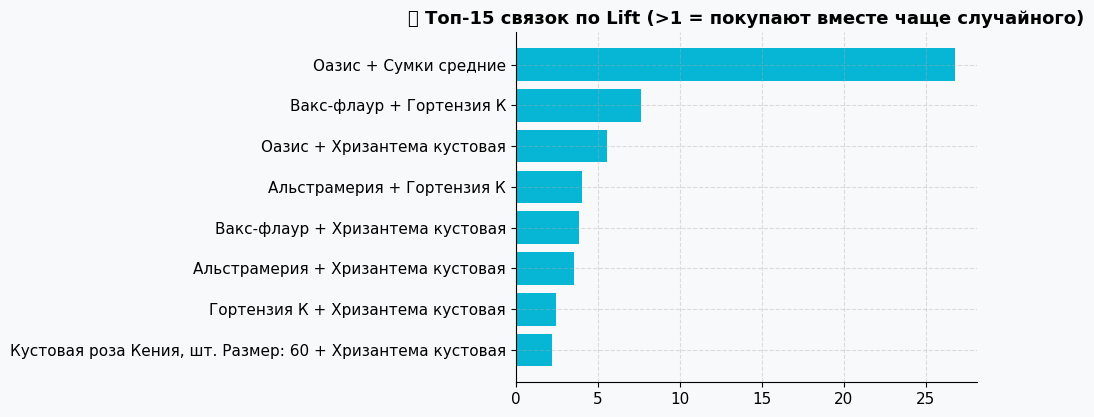

In [ ]:

bk_src = df_s[~df_s['Категория'].isin(EXCLUDE_FROM_BASKET)]
chk = df_s.groupby('check_key').agg(Выручка=('Выручка','sum'), Позиций=('Товар','count'), Штук=('Кол-во','sum'))
fig, axes = plt.subplots(1,2, figsize=(13,4.5))
sz = chk['Позиций'].clip(upper=10).value_counts().sort_index()
axes[0].bar(sz.index.astype(str), sz.values, color=PALETTE[0])
axes[0].set_title('Сколько позиций в чеке'); axes[0].set_xlabel('позиций'); axes[0].set_ylabel('чеков')
for i,(x,y) in enumerate(zip(sz.index.astype(str), sz.values)):
    axes[0].text(i, y, int(y), ha='center', va='bottom', fontsize=9)
dist = chk['Выручка']
axes[1].hist(dist[dist>0], bins=40, color=PALETTE[1])
axes[1].axvline(dist.median(), color='red', ls='--', label=f'медиана {rub(dist.median())}')
axes[1].set_title('Распределение сумм чеков'); axes[1].legend(); axes[1].xaxis.set_major_formatter(mticker.FuncFormatter(fmt_rub_axis))
plt.tight_layout(); plt.show()

baskets = bk_src.groupby('check_key')['Товар'].apply(set)
n_b = len(baskets)
cnt = Counter(); pair_cnt = Counter()
for b in baskets:
    cnt.update(b)
    for p in combinations(sorted(b), 2): pair_cnt[p]+=1
rows=[]
for (a,b),c in pair_cnt.items():
    if c < MIN_PAIR_COUNT: continue
    sup = c/n_b; lift = c*n_b/(cnt[a]*cnt[b])
    conf_ab = c/cnt[a]; conf_ba = c/cnt[b]
    if sup >= MIN_SUPPORT and lift > 1:
        rows.append({'Товар A':a,'Товар B':b,'Чеков с парой':c,'Поддержка %':sup*100,
                     'Lift':lift,'Конф. A→B':conf_ab*100,'Конф. B→A':conf_ba*100})
mb = pd.DataFrame(rows).sort_values('Lift', ascending=False)
if len(mb):
    print(f'✅ Пар найдено: {len(mb)}. Топ-10 связок:')
    display(mb.head(10).round(2))
    fig, ax = plt.subplots(figsize=(10, .35*min(15,len(mb))+1.5))
    t = mb.head(15)[::-1]
    ax.barh([f'{a} + {b}' for a,b in zip(t['Товар A'],t['Товар B'])], t['Lift'], color=PALETTE[6])
    ax.set_title('🧺 Топ-15 связок по Lift (>1 = покупают вместе чаще случайного)')
    plt.tight_layout(); plt.show()
else:
    print('ℹ️ Заметных пар нет (мало многопозиционных чеков или маленький период).')



<a id='шаг14'></a>
# 14. 💹 Цены и маржа: где теряем деньги

Три проблемы:
1. **Много оборота, мало маржи** — «крутят магазин впустую»;
2. **Нулевая/отрицательная маржа** — продаём ниже закупки (частая ошибка: забыли переписать цену после подорожания поставки);
3. **Низкая наценка относительно категории** — можно поднять цену, спрос устойчив (класс AX).


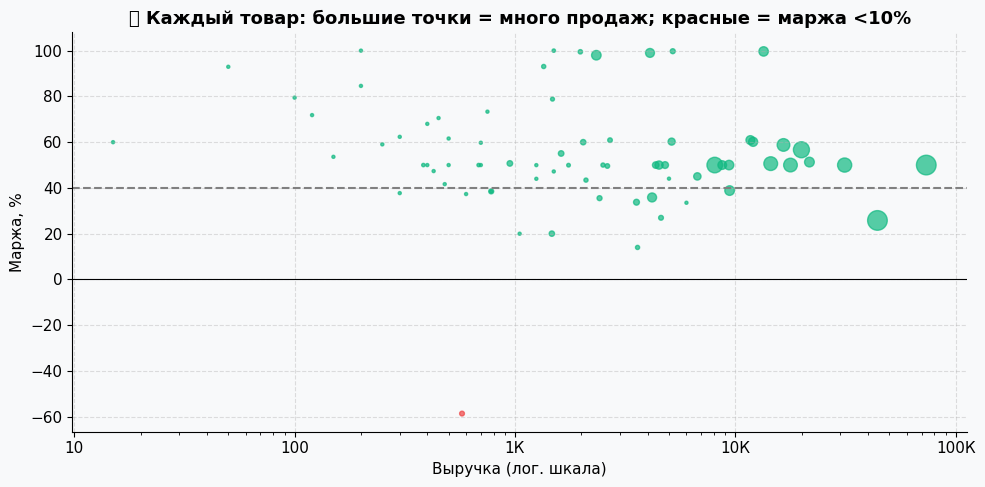

🚨 Товаров с маржой <10% (или отрицательной): 1


,Товар,Выручка,Маржа,Маржа %,Продано,Средняя_цена
31,Оазис,575.04,-336.96,-58.597663,12.0,47.92


⚠️ Ходовые, но низкомаржинальные (<40%): 8


,Товар,Выручка,Маржа %,Продано
65,Хризантема одноголовая К,44151.12,25.800297,234.0
9,Георгины,9420.00,38.853503,48.0
40,Протея люкс,6000.00,33.527000,3.0
29,Лилия 5+,4599.96,26.955887,12.0
53,Сантини,4189.92,35.846030,42.0
0,Алиум,3600.00,14.000000,9.0
55,Скимия,3560.04,33.764789,18.0
8,Гелиантус,2419.95,35.535858,13.0


In [ ]:

pm = df_s[~df_s['Возврат']].groupby('Товар').agg(
    Выручка=('Выручка','sum'), Маржа=('Маржа','sum'), Продано=('Кол-во','sum'),
    Себестоимость=('Себестоимость','sum'), Средняя_цена=('Цена продажи','mean')).reset_index()
pm['Маржа %'] = np.where(pm['Выручка']>0, pm['Маржа']/pm['Выручка']*100, np.nan)
pm['Наценка %'] = np.where(pm['Себестоимость']>0, pm['Маржа']/pm['Себестоимость']*100, np.nan)

neg = pm[(pm['Маржа']<0)|(pm['Маржа %']<10)].sort_values('Маржа')
low = pm[(pm['Маржа %']<MARGIN_TARGET)&(pm['Выручка']>pm['Выручка'].quantile(.5))].sort_values('Выручка',ascending=False)

fig, ax = plt.subplots(figsize=(10,5))
samp = pm[pm['Выручка']>0].sample(min(400,(pm['Выручка']>0).sum()), random_state=1)
sc = ax.scatter(samp['Выручка'], samp['Маржа %'], s=samp['Продано'].clip(5,200),
                c=np.where(samp['Маржа %']<10, PALETTE[3], PALETTE[1]), alpha=.7)
ax.axhline(MARGIN_TARGET, ls='--', color='gray'); ax.axhline(0, color='black', lw=.8)
ax.set_xscale('log'); ax.set_xlabel('Выручка (лог. шкала)'); ax.set_ylabel('Маржа, %')
ax.set_title('💹 Каждый товар: большие точки = много продаж; красные = маржа <10%')
ax.xaxis.set_major_formatter(mticker.FuncFormatter(fmt_rub_axis))
plt.tight_layout(); plt.show()

print(f'🚨 Товаров с маржой <10% (или отрицательной): {len(neg)}')
if len(neg): display(neg[['Товар','Выручка','Маржа','Маржа %','Продано','Средняя_цена']].head(10))
print(f'⚠️ Ходовые, но низкомаржинальные (<{MARGIN_TARGET}%): {len(low)}')
if len(low): display(low[['Товар','Выручка','Маржа %','Продано']].head(10))



<a id='шаг15'></a>
# 15. 📦 Склад: «залежалый» товар и план закупки

Цветы — скоропорт: залежавшийся остаток = будущая списанная пачка.
* **Dead-stock** — нет продаж SLOW_DAYS дней.
* **План закупки** = скорость продаж (шт/день за последние COVER_LOOKBACK дней) × COVER_DAYS − текущий остаток.


In [ ]:

last_sale = df_s[~df_s['Возврат']].groupby('Товар')['Дата'].max()
st = stock.merge(last_sale.rename('Последняя продажа'), left_on='Товар', right_index=True, how='left')
today = _dmax
st['Дней без продаж'] = (today - st['Последняя продажа']).dt.days.fillna(9999)
dead = st[(st['Кон. остаток']>0)&(st['Дней без продаж']>=SLOW_DAYS)].sort_values('Остаток, ₽', ascending=False)
print(f'🧊 Залежалый товар (нет продаж {SLOW_DAYS}+ дн., но лежит на складе): {len(dead)} позиций на {rub(dead["Остаток, ₽"].sum()) if len(dead) else "0 ₽"}')
if len(dead): display(dead[['Товар','Категория','Кон. остаток','Остаток, ₽','Дней без продаж']].head(15))

win_start = _dmax - pd.Timedelta(days=COVER_LOOKBACK-1)
win = df_s[(df_s['Дата']>=win_start)&(~df_s['Возврат'])]
work_days = max(win['Дата'].dt.normalize().nunique(), 1)
speed = win.groupby('Товар')['Кол-во'].sum()/work_days
plan = stock[['Товар','Категория','Кон. остаток']].copy()
plan['Шт/день'] = plan['Товар'].map(speed).fillna(0)
plan['Нужно на %d дн.' % COVER_DAYS] = (plan['Шт/день']*COVER_DAYS).round(0)
plan['Заказать, шт'] = (plan[f'Нужно на {COVER_DAYS} дн.'] - plan['Кон. остаток']).clip(lower=0).round(0)
plan['Цена продажи'] = plan['Товар'].map(df_s.groupby('Товар')['Цена продажи'].mean())
plan['Сумма закупки, ₽'] = plan['Заказать, шт']*plan['Товар'].map(df_s[~df_s['Возврат']].groupby('Товар')['Себестоимость'].apply(lambda s: s.sum()/max(s.abs().sum(),1))).fillna(0)
buy = plan[(plan['Заказать, шт']>0)&(~plan['Категория'].isin(EXCLUDE_FROM_BASKET))].sort_values('Шт/день', ascending=False)
print(f'🛒 К заказу на {COVER_DAYS} дней: {len(buy)} позиций ориентировочно на {rub(buy["Сумма закупки, ₽"].sum())}')
display(buy[['Товар','Категория','Шт/день','Кон. остаток','Заказать, шт']].head(20))


🧊 Залежалый товар (нет продаж 21+ дн., но лежит на складе): 160 позиций на 182 335 ₽


,Товар,Категория,Кон. остаток,"Остаток, ₽",Дней без продаж
413,фаленопсис каскад микс 12/50,Горшечные растения,7.0,9520.00,9999.0
44,Астильба,Прочая срезка,101.0,7191.20,9999.0
61,Букет 9 одноголовых хризантем,Хризантемы,7.0,6300.00,9999.0
158,Каллы,Прочая срезка,45.0,5160.00,9999.0
33,антуриум 23/40,Горшечные растения,3.0,4800.00,9999.0
253,Матиола,Прочая срезка,56.0,4525.00,9999.0
97,Гиперекум,Прочая срезка,38.0,3846.60,9999.0
393,Танацетум,Зелень и наполнители,28.0,3811.32,9999.0
159,Каллы высокие,Прочая срезка,31.0,3664.00,9999.0
89,Георгина 12,Прочая срезка,21.0,3659.25,9999.0


🛒 К заказу на 4 дней: 15 позиций ориентировочно на 146 ₽


,Товар,Категория,Шт/день,Кон. остаток,"Заказать, шт"
442,Хризантема одноголовая К,Хризантемы,18.000000,48.0,24.0
225,"Кустовая роза Кения, шт. Размер: 60",Розы,8.000000,0.0,32.0
335,"Роза микс Э, шт. Размер: 50",Розы,7.461538,0.0,30.0
345,"Роза пионовидная Э, шт. размер: 60",Розы,3.615385,0.0,14.0
337,"Роза микс Э, шт. Размер: 70",Розы,3.000000,0.0,12.0
339,"Роза микс, шт. Размер: 50",Розы,2.692308,-1.0,12.0
98,Гипсофила,Зелень и наполнители,2.000000,0.0,8.0
13,Алиум,Горшечные растения,0.692308,0.0,3.0
224,"Кустовая роза Кения, шт. Размер: 50",Розы,0.692308,0.0,3.0
388,Сумки средние,Упаковка и аксессуары,0.615385,1.0,1.0



<a id='шаг16'></a>
# 16. 🔮 Прогноз выручки на FORECAST_DAYS дней

На короткой истории (~1 месяц) сложные модели (Prophet, нейросети) вредны — запоминают шум. Честный минимум: **медиана по одноимённым дням недели за последние 8 недель**. Так же сравниваем альтернативы и показываем, какая ошибается меньше (backtest).


ℹ️ Истории меньше 3 недель — backtest пропускаем.
📉 Средняя ошибка прогноза (backtest, ₽): {'по дню недели': '—', 'среднее за 28 дн.': '—', 'наивный (вчера)': '—'} → лучший: по дню недели


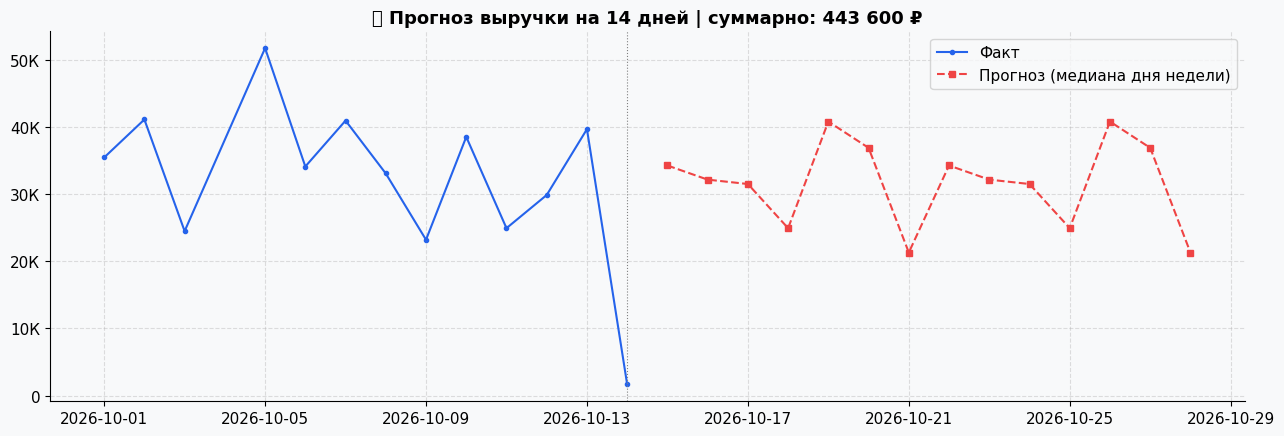

In [ ]:

series = daily.set_index('День')['Выручка'].asfreq('D')
hist = series.dropna()

def predict_dow(h, target, weeks=8):
    same = h[(h.index.dayofweek==target.dayofweek) & (h.index >= target-pd.Timedelta(weeks=weeks))]
    if len(same)==0: same = h[h.index.dayofweek==target.dayofweek]
    return same.median() if len(same) else h.mean()

# backtest на последних 14 днях истории (если данных мало — пропускаем)
bt_dates = hist.index[-14:] if len(hist) >= 21 else hist.index[:0]
err = {}
if len(bt_dates)==0:
    print('ℹ️ Истории меньше 3 недель — backtest пропускаем.')
for name, fn in [('по дню недели', lambda h,t: predict_dow(h,t)),
                 ('среднее за 28 дн.', lambda h,t: h.tail(28).mean()),
                 ('наивный (вчера)', lambda h,t: h.iloc[-1])]:
    preds = [fn(hist[hist.index<d], d) for d in bt_dates]
    err[name] = np.mean(np.abs(np.array(preds)-hist.loc[bt_dates].values))
best = min(err, key=err.get) if err else '—'
print('📉 Средняя ошибка прогноза (backtest, ₽):', {k: rub(v) for k,v in err.items()}, f'→ лучший: {best}')

future = pd.date_range(series.index.max()+pd.Timedelta(days=1), periods=FORECAST_DAYS, freq='D')
fc = pd.Series([predict_dow(hist,d) for d in future], index=future)
fig, ax = plt.subplots(figsize=(13,4.5))
ax.plot(hist.index, hist.values, marker='o', ms=3, color=PALETTE[0], label='Факт')
ax.plot(fc.index, fc.values, marker='s', ms=5, color=PALETTE[3], ls='--', label=f'Прогноз (медиана дня недели)')
ax.axvline(series.index.max(), color='gray', lw=.8, ls=':')
ax.yaxis.set_major_formatter(mticker.FuncFormatter(fmt_rub_axis)); ax.legend()
ax.set_title(f'🔮 Прогноз выручки на {FORECAST_DAYS} дней | суммарно: {rub(fc.sum())}')
plt.tight_layout(); plt.show()



<a id='шаг17'></a>
# 17. 🕵️ ДЕТЕКТОР ПОТЕРЬ И ХИЩЕНИЙ

Здесь блокнот превращается в **аудитора**. Помня способы из раздела 2, ищем статистические аномалии:

| Проверка | Что ищет | Какой способ хищения ловит |
|---|---|---|
| 17.1 Невязки остатков | нач+приход−расход ≠ кон | прямая кража, потерянные документы (#11) |
| 17.2 Аномальные списания | дни, где списания ≫ обычных | ложная «порча» (#6,#7) |
| 17.3 Профиль списаний | кто списывает и что именно | «любимчик» воришки — ходовые розы (#6) |
| 17.4 Возвраты чеков | возвраты вне графика, всплески у одного человека, возвраты без последующей продажи | «минусовка» (#1) |
| 17.5 Сверка Движение ↔ Касса | товар ушёл, денег нет | непробитая продажа (#2) |
| 17.6 Скидки/цены по сменам | средняя цена продажи ниже прайса у одного сотрудника | занижение суммы (#3) |
| 17.7 Пересортица | плюс SKU = минус SKU в один день | #9 |

> Результаты — **повод для проверки**, а не приговор. Пороги настраиваются в ячейке 3.


In [ ]:

alerts = []

# ---- 17.1 Невязки остатков ----
if len(bad):
    for _,r in bad.sort_values('Невязка, шт').iterrows():
        alerts.append({'Проверка':'17.1 Невязка остатков','Объект':r['Товар'],
                       'Метрика':f'{r["Невязка, шт"]:+.0f} шт',
                       'Комментарий':'Расход+приход не сходится с остатком — возможная кража или незадокументированное движение'})

# ---- 17.2 Дневные списания: аномальные дни (z-score по дням со списаниями) ----
wo_daily = docs_f[docs_f['Это_списание']].groupby(docs_f['Дата'].dt.normalize())['Расход (себест.)'].sum()
if len(wo_daily)==0 and 'Списания' in extra:      # строим дневную кривую списаний из отдельного файла
    sb = extra['Списания']
    dcol = next((c for c in sb.columns if any(w in norm_name(c) for w in ['дата','от '])), None)
    scol = next((c for c in sb.columns if 'сумма' in norm_name(c)), None)
    if dcol and scol:
        tmp_sb = pd.DataFrame({'d': pd.to_datetime(sb[dcol], dayfirst=True, errors='coerce'), 's': to_num(sb[scol])}).dropna()
        wo_daily = tmp_sb.groupby(tmp_sb['d'].dt.normalize())['s'].sum()
print(f'🗑 Источник данных о списаниях: {wo_source}, всего за период: {rub(wo_daily.sum()) if len(wo_daily) else rub(wo_sum)}')
if len(wo_daily) >= 5:
    med = wo_daily.median(); mad = (wo_daily-med).abs().median()
    spike_days = wo_daily[wo_daily > med*WRITEOFF_SPIKE_KOEF + 3*mad*1.4826]
    for d,v in spike_days.items():
        alerts.append({'Проверка':'17.2 Пик списаний','Объект':f'{d:%d.%m.%Y}',
                       'Метрика':rub(v),
                       'Комментарий':f'Списание в {v/med:.1f}× выше типичного дня ({rub(med)}) — проверить акты и камеры'})
    print(f'🗑 Списания: всего {rub(wo_daily.sum())} за {len(wo_daily)} дн., типичный день {rub(med)}, максимум {rub(wo_daily.max())} ({wo_daily.idxmax():%d.%m})')
    fig, ax = plt.subplots(figsize=(12,3.8))
    cols = [PALETTE[3] if v>med*WRITEOFF_SPIKE_KOEF else PALETTE[0] for v in wo_daily]
    ax.bar(wo_daily.index, wo_daily.values, color=cols)
    ax.axhline(med*WRITEOFF_SPIKE_KOEF, ls='--', color=PALETTE[3], label=f'порог ×{WRITEOFF_SPIKE_KOEF}')
    ax.set_title('Ежедневные списания (красные — аномальные дни)'); ax.legend()
    ax.yaxis.set_major_formatter(mticker.FuncFormatter(fmt_rub_axis)); plt.tight_layout(); plt.show()

# ---- 17.3 Что именно списываем: ходовые позиции не должны «засыхать» массово ----
wo_lines = docs_f[docs_f['Это_списание']].groupby('Товар').agg(Шт=('Расход, шт','sum'), Сумма=('Расход (себест.)','sum'))
if len(wo_lines)==0 and 'Списания' in extra:
    sb = extra['Списations'] if False else extra['Списания']
    ncol = next((c for c in sb.columns if any(w in norm_name(c) for w in ['наименован','товар'])), None)
    qcol = next((c for c in sb.columns if 'кол' in norm_name(c)), None)
    scol = next((c for c in sb.columns if 'сумма' in norm_name(c)), None)
    if ncol and scol:
        t = pd.DataFrame({'Товар': sb[ncol].astype(str).str.strip(),
                          'Шт': to_num(sb[qcol]) if qcol else np.nan, 'Сумма': to_num(sb[scol])})
        t = t[t['Товар'].str.len()>2]
        wo_lines = t.groupby('Товар').sum(min_count=1)
sold_rank = df_s[~df_s['Возврат']].groupby('Товар')['Кол-во'].sum().rank(pct=True)
wo_lines['Ранг продаж'] = wo_lines.index.map(sold_rank)
suspect_wo = wo_lines[(wo_lines['Ранг продаж']>0.7)&(wo_lines['Сумма']>0)].sort_values('Сумма',ascending=False)
if len(suspect_wo):
    display(suspect_wo.head(10))
    print('↑ Списываются ТОВАРЫ ИЗ ТОП-30% по продажам — классический след «ложной порчи» (#6). Сверьте с актами/фото.')

# ---- 17.4 Возвраты чеков ----
rets = df_s[df_s['Возврат']].copy()
if len(rets):
    ret_daily = rets.groupby(rets['Дата'].dt.normalize()).size()
    checks_daily = df_s.groupby(df_s['Дата'].dt.normalize())['check_key'].nunique()
    rate = (ret_daily/checks_daily*100).fillna(0)
    late = rets[rets['Час'].notna() & (rets['Час']>=18)]
    print(f'↩️ Возвратов: {len(rets)} позиций ({rate.mean():.1f}% чеков в среднем). Из них после 18:00 — {len(late)} ({len(late)/len(rets)*100:.0f}%)')
    if rate.mean()>RETURN_RATE_ALERT:
        alerts.append({'Проверка':'17.4 Возвраты','Объект':'весь магазин','Метрика':f'{rate.mean():.1f}%',
                       'Комментарий':'высокая доля возвратов — выборка журналов отмен'})
    worst_days = rate.sort_values(ascending=False).head(3)
    for d,v in worst_days.items():
        alerts.append({'Проверка':'17.4 Пик возвратов','Объект':f'{d:%d.%m.%Y}','Метрика':f'{v:.0f}% чеков',
                       'Комментарий':'всплеск возвратов — проверить отмены этого дня (камера + журнал)'})
    fig, ax = plt.subplots(figsize=(12,3.5))
    ax.bar(rate.index, rate.values, color=[PALETTE[3] if v>rate.quantile(.9) else PALETTE[4] for v in rate])
    ax.set_title('Доля чеков с возвратом по дням'); plt.tight_layout(); plt.show()
    # возвраты без «второй жизни»: товар вернули и в тот же день снова не продали
    no_resale = []
    for _,r in rets.iterrows():
        again = df_s[(~df_s['Возврат'])&(df_s['Товар']==r['Товар'])&(df_s['Дата']>r['Дата'])]
        if len(again)==0: no_resale.append(r['Товар'])
    if no_resale:
        print(f'⚠️ После возврата товар так и не продался ни разу: {len(no_resale)} позиций — часть может быть «возвратом на бумаге» (#1).')

# ---- 17.5 Сверка Движение ↔ Касса (если есть кассовый файл) ----
if cash is not None and len(cash):
    ccol = next((c for c in cash.columns if 'итого' in c.lower() or 'выручка' in c.lower()), None)
    rev_cash = cash[[ 'Дата', ccol]].copy() if ccol else None
    if rev_cash is not None:
        rev_cash['ccol'] = to_num(rev_cash[ccol])
        mv_daily = df_s.groupby(df_s['Дата'].dt.normalize())['Выручка'].sum()
        cmp = pd.DataFrame({'Касса': rev_cash.set_index('Дата')['ccol'], 'БизнесРу': mv_daily}).dropna()
        cmp['Разница'] = cmp['БизнесРу'] - cmp['Касса']
        cmp['Разница %'] = np.where(cmp['Касса']>0, cmp['Разница']/cmp['Касса']*100, np.nan)
        big = cmp[cmp['Разница %'].abs()>5]
        print(f'🧮 Сверка «Бизнес.Ру vs Касса»: дней {len(cmp)}, с расхождением >5%: {len(big)}')
        for d,r in big.head(10).iterrows():
            alerts.append({'Проверка':'17.5 Движение↔Касса','Объект':f'{d:%d.%m.%Y}',
                           'Метрика':f'{r["Разница %"]:+.1f}%',
                           'Комментарий':'товар по документу ушёл, денег в кассе нет (или наоборот) — непробитая продажа (#2)'})

# ---- 17.6 Цены по сменам (кто продаёт дешевле прайса) ----
price_ref = df_s.groupby('Товар')['Цена продажи'].median()
tmp = df_s[~df_s['Возврат']].copy()
tmp['отклонение'] = tmp.apply(lambda r: (r['Цена продажи']-price_ref.get(r['Товар'],np.nan))/price_ref.get(r['Товар'],np.nan)*100 if price_ref.get(r['Товар'],0) else np.nan, axis=1)
disc_days = tmp[tmp['отклонение']<-15].groupby(tmp['Дата'].dt.normalize()).size()
if len(disc_days):
    print(f'💸 Позиций проданных >15% ниже медианной цены: {int((tmp["отклонение"]<-15).sum())} —пиковые дни: {dict(disc_days.sort_values(ascending=False).head(5).astype(int))}')

# ---- 17.7 Пересортица: плюс одного = минус другого в один день ----
mv_by_day_item = docs_f.groupby([docs_f['Дата'].dt.normalize(),'Товар'])['Расход, шт'].sum()
cross = []
for d, grp in mv_by_day_item.groupby(level=0):
    neg = grp[grp<=-5]; pos = grp[grp>=5]
    if len(neg) and len(pos):
        cross.append({'Дата': d, 'Минус': ', '.join(neg.index.get_level_values(1)[:3]),
                      'Плюс': ', '.join(pos.index.get_level_values(1)[:3])})
if cross:
    print(f'🔄 Дней с одновременным «плюсом» и «минусом» крупных партий (возможная пересортица #9): {len(cross)}')

# ---- Итоговая таблица алертов ----
alert_df = pd.DataFrame(alerts)
print('\n' + '='*60)
print(f'🚨 ИТОГО сигналов к проверке: {len(alert_df)}')
print('='*60)
if len(alert_df): display(alert_df)
else: print('✅ Явных аномалий не найдено. Это хорошо — но не отменяет регулярных слепых инвентаризаций.')


🗑 Источник данных о списаниях: файл «Списания», всего за период: 0 ₽
🧮 Сверка «Бизнес.Ру vs Касса»: дней 13, с расхождением >5%: 2
💸 Позиций проданных >15% ниже медианной цены: 4 —пиковые дни: {Timestamp('2026-10-01 00:00:00'): np.int64(1), Timestamp('2026-10-08 00:00:00'): np.int64(1), Timestamp('2026-10-09 00:00:00'): np.int64(1), Timestamp('2026-10-11 00:00:00'): np.int64(1)}

🚨 ИТОГО сигналов к проверке: 2


,Проверка,Объект,Метрика,Комментарий
0,17.5 Движение↔Касса,07.10.2026,+6.6%,"товар по документу ушёл, денег в кассе нет (ил..."
1,17.5 Движение↔Касса,11.10.2026,-7.3%,"товар по документу ушёл, денег в кассе нет (ил..."



<a id='шаг18'></a>
# 18. 📋 Итоговое резюме — что сказать владельцу

Блокнот сам формулирует главные цифры периода текстом.


In [ ]:

top3 = abc_rev.head(3)['Товар'].tolist()
share_top = abc_rev[abc_rev['Класс']=='A']
worst_wo_day = wo_daily.idxmax() if len(wo_daily) else None
worst_str = f'{worst_wo_day:%d.%m} ({rub(wo_daily.max())})' if len(wo_daily) else 'нет'
print(f'''
🧾 РЕЗЮМЕ ЗА ПЕРИОД {_dmin:%d.%m} — {_dmax:%d.%m}
──────────────────────────────────────────────
• Выручка {rub(total_rev)}, валовая маржа {rub(total_margin)} ({pct(margin_pct)}; цель {MARGIN_TARGET}%).
• Чеков {num_fmt(n_checks)}, средний чек {rub(avg_check)}, в чеке в среднем {items_per_chk:.1f} позиции.
• Класс A: {len(share_top)} товаров дают 80% выручки. Топ-3: {", ".join(top3)}.
• Списания: {rub(wo_sum)} ({wo_sum/total_cost*100 if total_cost else 0:.1f}% от себестоимости продаж). Самый крупный день списаний — {worst_str}.
• Залежалый товар: {len(dead)} позиций на {rub(dead["Остаток, ₽"].sum()) if len(dead) else "0 ₽"}.
• К заказу на {COVER_DAYS} дней: {len(buy)} позиций (~{rub(buy["Сумма закупки, ₽"].sum())}).
• Сигналов аудит-детектора: {len(alert_df)}.
──────────────────────────────────────────────
''')
print('✅ Анализ завершён. Ниже — выгрузка всех таблиц в Excel.')



🧾 РЕЗЮМЕ ЗА ПЕРИОД 01.10 — 14.10
──────────────────────────────────────────────
• Выручка 418 678 ₽, валовая маржа 212 802 ₽ (50.8%; цель 40%).
• Чеков 248, средний чек 1 688 ₽, в чеке в среднем 2.2 позиции.
• Класс A: 18 товаров дают 80% выручки. Топ-3: Роза микс Э, шт. Размер: 60, Хризантема одноголовая К, Кустовая роза Кения, шт. Размер: 60.
• Списания: 0 ₽ (0.0% от себестоимости продаж). Самый крупный день списаний — нет.
• Залежалый товар: 160 позиций на 182 335 ₽.
• К заказу на 4 дней: 15 позиций (~146 ₽).
• Сигналов аудит-детектора: 2.
──────────────────────────────────────────────

✅ Анализ завершён. Ниже — выгрузка всех таблиц в Excel.



<a id='шаг19'></a>
# 19. 💾 Выгрузка всех таблиц в один Excel

Каждый раздел — отдельный лист. Отдавайте файл владельцу/закрывайте по нему совещание.


In [ ]:

if not EXPORT_XLSX:
    print('Выгрузка отключена (EXPORT_XLSX=False).')
else:
    os.makedirs(OUTPUT_DIR, exist_ok=True)
    out = os.path.join(OUTPUT_DIR, 'Отчет_розница_цветы.xlsx')
    sheets = {
        'KPI': pd.DataFrame([{'показатель':k,'значение':v} for k,v in kpis]),
        'Динамика_день': daily,
        'ABC_выручка': abc_rev, 'ABC_маржа': abc_marg,
        'Категории': cat,
        'Товары_маржа': pm.sort_values('Выручка',ascending=False),
        'MarketBasket': mb if len(mb) else pd.DataFrame(),
        'Остатки': stock, 'Залежалый': dead, 'План_закупки': buy,
        'Списания_дни': wo_daily.rename('Сумма').reset_index() if len(wo_daily) else pd.DataFrame(),
        'Алерты': alert_df,
        'Прогноз': fc.rename('Прогноз').reset_index().rename(columns={'index':'Дата'}),
        'Чеки_позиции': df_s,
    }
    with pd.ExcelWriter(out, engine='openpyxl') as xw:
        for name, d in sheets.items():
            (d if isinstance(d,pd.DataFrame) else pd.DataFrame()).to_excel(xw, sheet_name=name[:31], index=False)
    print(f'💾 Сохранено: {out}')


💾 Сохранено: output/Отчет_розница_цветы.xlsx



<a id='шаг20'></a>
# 20. 🚀 Куда развивать: Data Science, продуктовая аналитика и BI

**Уровень 1 — сейчас (диагностика).** Этот блокнот: что было.
**Уровень 2 — мониторинг (BI).** Раз в неделю обновляете файлы из Бизнес.Ру → получаете Excel. Дальше: подключить Jupyter к расписанию (cron / планировщик Windows), затем — дашборд в **Apache Superset / Grafana / Яндекс DataLens** (бесплатно) поверх той же таблицы чеков. Owner дашборда — вы.
**Уровень 3 — предиктив (ML).**
* Прогноз спроса по SKU (LightGBM с признаками: день недели, праздник, погода, цена) → точная закупка вместо «среднего ×4 дня». Цветы хранятся 5–7 дней, поэтому экономия на списаниях — самая вкусная метрика.
* Кластеризация клиентов по RFM (нужны карты лояльности из Бизнес.Ру) → сегменты и рассылки.
* Time-series аномалии (Isolation Forest по дневным векторам «выручка/чеки/средний чек/скидки по сотруднику») → автоматический аудит вместо правил из раздела 17.
**Уровень 4 — продуктовая аналитика.**
* Воронка онлайн-заказа (сайт/Авито/2ГИК: просмотр → корзина → оплата) — считается как продуктовые метрики: конверсия, CAC, LTV.
* A/B тесты витрины и составов букетов: «тест — это не мнение, а сравнение двух чисел с доверительным интервалом».
* North Star metric магазина — например «маржа с повторных покупок в месяц».
**Уровень 5 — автоматизация учёта.** API Бизнес.Ру (у сервиса есть REST API с токеном) → скрипт сам тянет Движение каждый вечер → те же ноутбуки работают без ручных выгрузок. Следующий шаг — база данных (PostgreSQL) и dbt-подобные «слои»: сырые данные → витрина чеков → дашборд.

### Мини-словарь для общения с данными
| Термин | Простыми словами |
|---|---|
| KPI | главная измеримая цель (маржа %, средний чек) |
| ETL | достать данные → почистить → загрузить в удобный вид |
| ABC/XYZ | «кто приносит деньги» / «насколько ровно» |
| Lift | во сколько раз пара встречается вместе чаще случайного |
| Backtest | проверить модель на прошлом: насколько она угадывала |
| RFM | Recent/Frequency/Money — три вопроса о клиенте |
| BI-дашборд | живые графики вместо одноразового отчёта |
